In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
dataset='/content/drive/MyDrive/Cropped Rice 6 Class'

In [ ]:
!pip install split-folders

import splitfolders


input_folder='/content/drive/MyDrive/Cropped Rice 6 Class'
output_folder = '/content/dataset_split'


splitfolders.ratio(
    input_folder,
    output=output_folder,
    seed=42,
    ratio=(0.8, 0.10, 0.10),
    group_prefix=None,
    move=False
)

Copying files: 1797 files [00:27, 65.46 files/s] 


In [ ]:
import os
import pandas as pd

# ระบุ Path ที่เก็บโฟลเดอร์ผลลัพธ์จากการ split
dataset_dir = '/content/dataset_split'

# นามสกุลไฟล์รูปภาพที่ต้องการนับ
image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff')

def count_images(folder_path):
    if not os.path.exists(folder_path):
        return 0
    return sum(1 for f in os.listdir(folder_path) if f.lower().endswith(image_extensions))

# ดึงรายชื่อคลาสทั้งหมดจากโฟลเดอร์ train
classes = sorted(os.listdir(os.path.join(dataset_dir, 'train')))

data = []
for idx, cls in enumerate(classes, start=1):
    train_count = count_images(os.path.join(dataset_dir, 'train', cls))
    val_count = count_images(os.path.join(dataset_dir, 'val', cls))
    test_count = count_images(os.path.join(dataset_dir, 'test', cls))

    data.append({
        'ลำดับ': idx,
        'ชื่อพันธุ์ข้าว': cls,
        'Training': train_count,
        'Validation': val_count,
        'Testing': test_count,
        'รวม': train_count + val_count + test_count
    })

# สร้าง DataFrame
df = pd.DataFrame(data)

# เพิ่มแถวสรุปผลรวมทั้งหมด (Total)
total_row = {
    'ลำดับ': '',
    'ชื่อพันธุ์ข้าว': 'รวมทั้งหมด',
    'Training': df['Training'].sum(),
    'Validation': df['Validation'].sum(),
    'Testing': df['Testing'].sum(),
    'รวม': df['รวม'].sum()
}
df_total = pd.concat([df, pd.DataFrame([total_row])], ignore_index=True)

# แสดงผลตาราง
display(df_total)

# บันทึกเป็นไฟล์ Excel หรือ CSV ไปใส่ในเล่มรายงานได้ทันที
df_total.to_excel('/content/dataset_summary.xlsx', index=False)

,ลำดับ,ชื่อพันธุ์ข้าว,Training,Validation,Testing,รวม
0,1,R1,240,30,30,300
1,2,R2,238,29,31,298
2,3,R3,240,30,30,300
3,4,R4,240,30,30,300
4,5,R5,240,30,30,300
5,6,R6,239,29,31,299
6,,รวมทั้งหมด,1437,178,182,1797


# หา layer หาlayer ที่ดีที่สุด

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report

# ----------------------------------------------------
# 1. Initialization and Dataset Preparation
# ----------------------------------------------------
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = 6
DATASET_DIR = '/content/dataset_split'

train_dir = os.path.join(DATASET_DIR, 'train')
val_dir = os.path.join(DATASET_DIR, 'val')
test_dir = os.path.join(DATASET_DIR, 'test')

# Load datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=True
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)

class_names = train_ds.class_names
print("Class Names:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

y_test_true = np.concatenate([y for x, y in test_ds], axis=0)

# ----------------------------------------------------
# 2. Model Builder Function (Conv Layers -> GAP -> Softmax)
# ----------------------------------------------------
def build_conv_model(conv_filters):
    model = models.Sequential()
    model.add(layers.Rescaling(1./255, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)))

    for filters in conv_filters:
        model.add(layers.Conv2D(filters, (3, 3), activation='relu', padding='same'))
        model.add(layers.MaxPooling2D((2, 2)))

    model.add(layers.GlobalAveragePooling2D())
    model.add(layers.Dense(NUM_CLASSES, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# ----------------------------------------------------
# 3. Experiment Configuration and Execution (2-Layers & 3-Layers)
# ----------------------------------------------------
conv_experiments = {
    # CNN 2-Layers
    "CNN 2-Layers 16,32": [16, 32],
    "CNN 2-Layers 32,64": [32, 64],
    "CNN 2-Layers 64,128": [64, 128],
    "CNN 2-Layers 128,256": [128, 256],
    # CNN 3-Layers
    "CNN 3-Layers 16,32,64": [16, 32, 64],
    "CNN 3-Layers 32,64,128": [32, 64, 128],
    "CNN 3-Layers 64,128,256": [64, 128, 256],
    "CNN 3-Layers 128,256,512": [128, 256, 512]
}

histories = {}
results_summary = []

for exp_name, filters in conv_experiments.items():
    print(f"\n{'='*30} Running Experiment: {exp_name} {'='*30}")

    model = build_conv_model(filters)
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )
    histories[exp_name] = history.history

    # Evaluation metrics
    train_acc = history.history['accuracy'][-1]
    train_loss = history.history['loss'][-1]
    val_acc = history.history['val_accuracy'][-1]
    val_loss = history.history['val_loss'][-1]
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    # Predictions
    y_pred_probs = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # Classification Metrics
    p_macro = precision_score(y_test_true, y_pred, average='macro', zero_division=0)
    r_macro = recall_score(y_test_true, y_pred, average='macro', zero_division=0)
    f1_macro = f1_score(y_test_true, y_pred, average='macro', zero_division=0)

    p_weighted = precision_score(y_test_true, y_pred, average='weighted', zero_division=0)
    r_weighted = recall_score(y_test_true, y_pred, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_test_true, y_pred, average='weighted', zero_division=0)

    results_summary.append({
        'Model architecture': exp_name,
        'Train Acc': train_acc,
        'Train Loss': train_loss,
        'Val Acc': val_acc,
        'Val Loss': val_loss,
        'Test Acc': test_acc,
        'Test Loss': test_loss,
        'Precision (Macro)': p_macro,
        'Recall (Macro)': r_macro,
        'F1 (Macro)': f1_macro,
        'Precision (Weighted)': p_weighted,
        'Recall (Weighted)': r_weighted,
        'F1 (Weighted)': f1_weighted
    })

# ----------------------------------------------------
# 4. Results Summary and Export to Excel
# ----------------------------------------------------
df_results = pd.DataFrame(results_summary)
print("\n" + "="*80)
print("Experiment Summary: Convolutional Layer Architectures")
print("="*80)
print(df_results[['Model architecture', 'Train Acc', 'Val Acc', 'Test Acc', 'F1 (Weighted)']])

output_path = '/content/conv_architecture_results.xlsx'
df_results.to_excel(output_path, index=False)
print(f"\nResults successfully exported to: {output_path}")

# ----------------------------------------------------
# 5. Performance Comparison Plot
# ----------------------------------------------------
x = np.arange(len(df_results['Model architecture']))
width = 0.25

plt.figure(figsize=(14, 6))
plt.bar(x - width, df_results['Train Acc'], width, label='Train Accuracy', color='#2F75B6')
plt.bar(x, df_results['Val Acc'], width, label='Validation Accuracy', color='#ED7D31')
plt.bar(x + width, df_results['Test Acc'], width, label='Test Accuracy', color='#A6A6A6')

plt.xlabel('Model Architecture')
plt.ylabel('Accuracy')
plt.title('Performance Comparison of CNN Layer Architectures')
plt.xticks(x, df_results['Model architecture'], rotation=30, ha='right')
plt.ylim(0, 1.15)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), ncol=3)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# ทดลอง dense globaverage

Found 1437 files belonging to 6 classes.
Found 178 files belonging to 6 classes.
Found 182 files belonging to 6 classes.
รายชื่อสายพันธุ์ข้าว: ['R1', 'R2', 'R3', 'R4', 'R5', 'R6']

============================== กำลังทดลอง: Dense64 ==============================
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 96ms/step - accuracy: 0.1628 - loss: 1.7922 - val_accuracy: 0.1685 - val_loss: 1.7837
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.2255 - loss: 1.7484 - val_accuracy: 0.2472 - val_loss: 1.7106
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.3243 - loss: 1.6204 - val_accuracy: 0.4888 - val_loss: 1.4677
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.4287 - loss: 1.4436 - val_accuracy: 0.5787 - val_loss: 1.3424
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.5685 - loss: 1.2493 - val_accuracy: 0.6180 - val_loss: 1.0979
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.6214 - loss: 1.0531 - val_accuracy: 0.6517 - val_loss: 1.0350
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 41ms/step - accuracy: 0.6653 - loss: 0.9135 - val_accuracy: 0.6966 - val_loss: 0.9505
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - accuracy: 0.6959 - loss: 0.8397 - val_accuracy: 0.6854 - val_loss: 0.

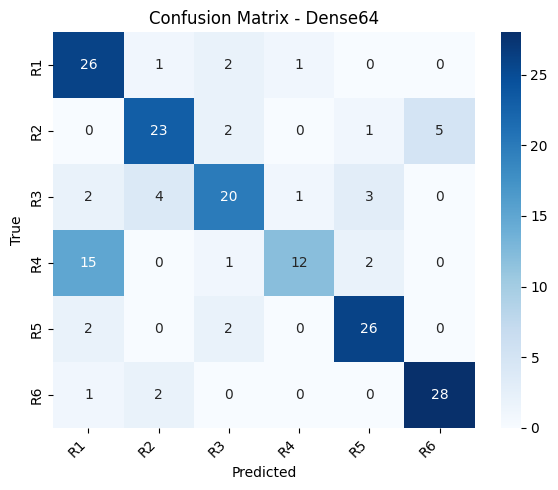


============================== กำลังทดลอง: Dense128 ==============================
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 95ms/step - accuracy: 0.1608 - loss: 1.7891 - val_accuracy: 0.2191 - val_loss: 1.7682
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.2644 - loss: 1.7102 - val_accuracy: 0.2303 - val_loss: 1.6973
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.4064 - loss: 1.5104 - val_accuracy: 0.5562 - val_loss: 1.3403
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.5358 - loss: 1.2468 - val_accuracy: 0.5225 - val_loss: 1.2235
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.5908 - loss: 1.1151 - val_accuracy: 0.6180 - val_loss: 1.0926
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.6381 - loss: 1.0050 - val_accuracy: 0.7191 - val_loss: 0.9182
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.7182 - loss: 0.8239 - val_accuracy: 0.7584 - val_loss: 0.7298
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.7279 - loss: 0.7477 - val_accuracy: 0.7135 - val_loss: 0.

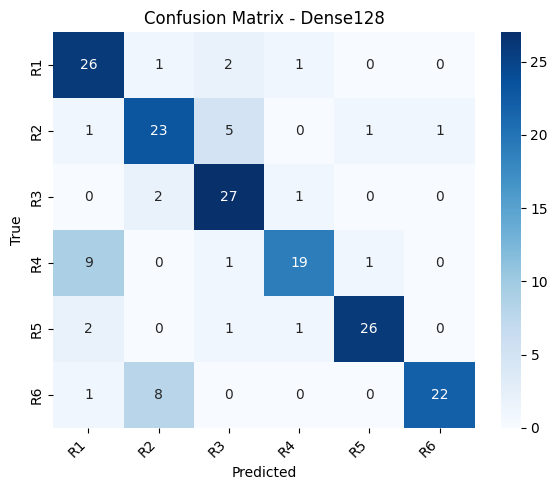


============================== กำลังทดลอง: Dense256 ==============================
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 95ms/step - accuracy: 0.1663 - loss: 1.7920 - val_accuracy: 0.2640 - val_loss: 1.7873
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.2324 - loss: 1.7570 - val_accuracy: 0.3258 - val_loss: 1.6103
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.3208 - loss: 1.6038 - val_accuracy: 0.3876 - val_loss: 1.4844
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.4537 - loss: 1.4103 - val_accuracy: 0.4101 - val_loss: 1.3379
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.5880 - loss: 1.1644 - val_accuracy: 0.6461 - val_loss: 0.9813
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.6785 - loss: 0.8941 - val_accuracy: 0.6067 - val_loss: 0.9613
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.7001 - loss: 0.7999 - val_accuracy: 0.7303 - val_loss: 0.8208
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.7216 - loss: 0.7478 - val_accuracy: 0.7753 - val_loss: 0.

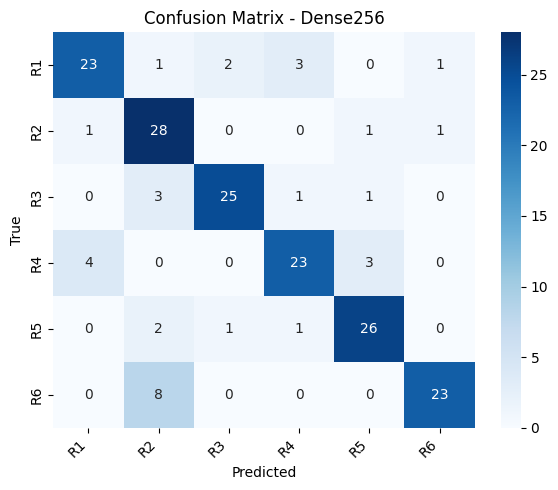


============================== กำลังทดลอง: Dense512 ==============================
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 96ms/step - accuracy: 0.1601 - loss: 1.7945 - val_accuracy: 0.1685 - val_loss: 1.7909
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.1914 - loss: 1.7853 - val_accuracy: 0.2079 - val_loss: 1.7624
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.2895 - loss: 1.6600 - val_accuracy: 0.3483 - val_loss: 1.5147
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.3466 - loss: 1.5377 - val_accuracy: 0.3708 - val_loss: 1.5281
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.4148 - loss: 1.4597 - val_accuracy: 0.5112 - val_loss: 1.3227
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.5546 - loss: 1.2365 - val_accuracy: 0.6292 - val_loss: 1.1433
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.6326 - loss: 1.0098 - val_accuracy: 0.7416 - val_loss: 0.8694
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.7056 - loss: 0.8267 - val_accuracy: 0.7079 - val_loss: 0.

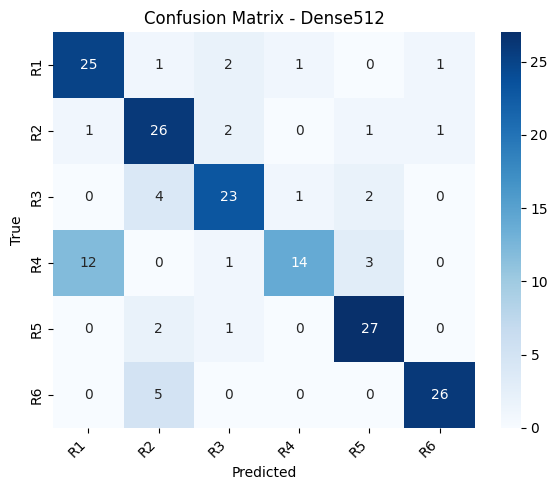


ตารางสรุปผลการทดลองทั้งหมด


,Model,Train Acc,Train Loss,Val Acc,Val Loss,Test Acc,Test Loss,Precision (Macro),Recall (Macro),F1 (Macro),Precision (Weighted),Recall (Weighted),F1 (Weighted)
0,Dense64,0.745999,0.710327,0.758427,0.636216,0.741758,0.963687,0.765125,0.740860,0.733205,0.765592,0.741758,0.734098
1,Dense128,0.769659,0.657647,0.797753,0.607605,0.785714,0.978916,0.806978,0.786380,0.786939,0.807082,0.785714,0.786657
2,Dense256,0.785665,0.577973,0.814607,0.554672,0.813187,0.959062,0.826848,0.813082,0.814881,0.826480,0.813187,0.814655
3,Dense512,0.777314,0.612641,0.820225,0.589119,0.774725,1.005228,0.792827,0.774014,0.769295,0.792976,0.774725,0.769825


บันทึกไฟล์สรุปผลเรียบร้อย: /content/experiment_results.xlsx


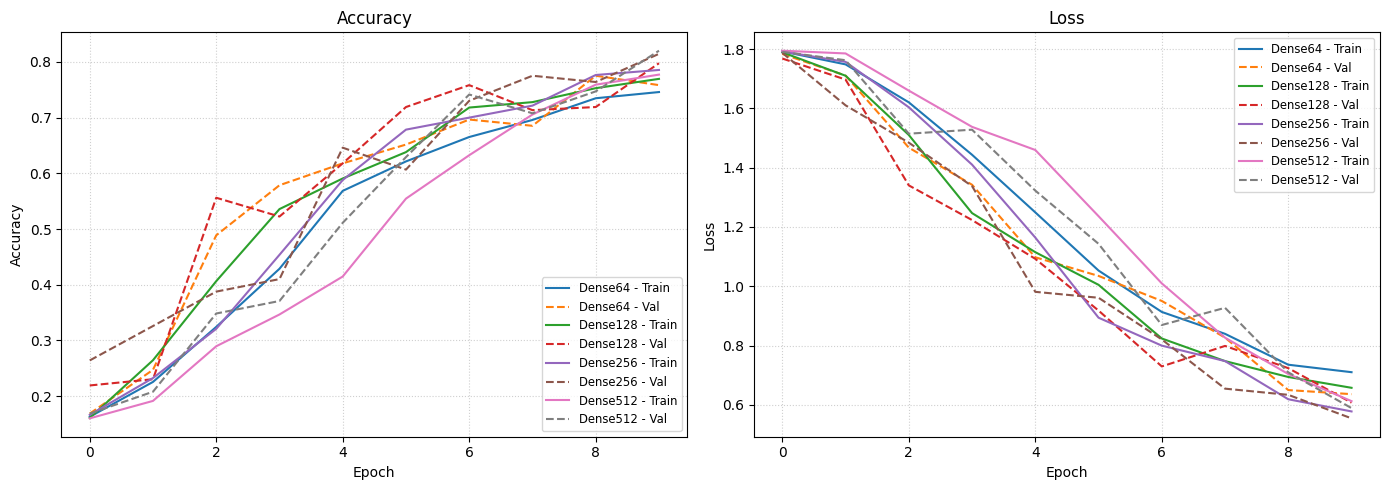

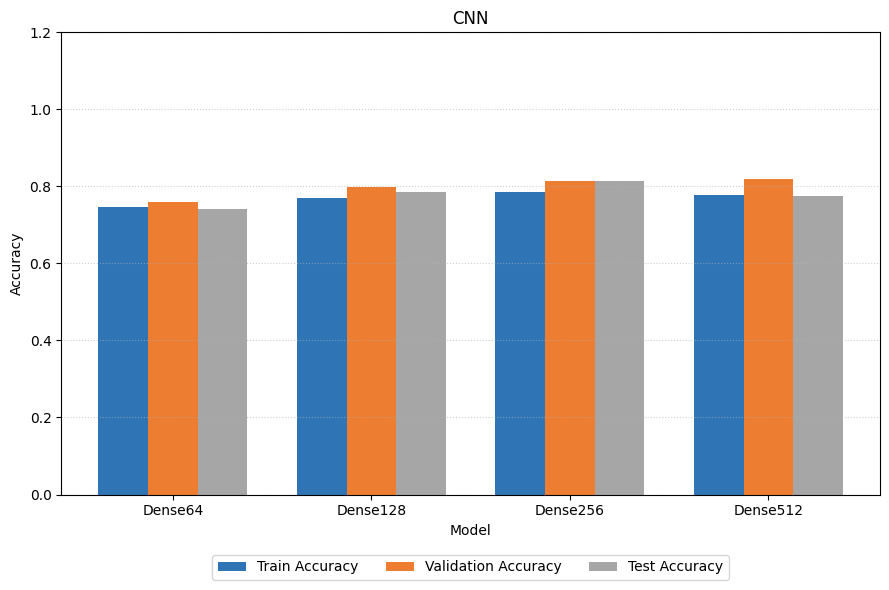

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# ----------------------------------------------------
# 1. กำหนดค่าเริ่มต้นและเตรียม Dataset
# ----------------------------------------------------
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
EPOCHS = 10         # กำหนด Epoch ตามที่ต้องการ (เช่น 10 epochs)
NUM_CLASSES = 6
DATASET_DIR = '/content/dataset_split'

train_dir = os.path.join(DATASET_DIR, 'train')
val_dir = os.path.join(DATASET_DIR, 'val')
test_dir = os.path.join(DATASET_DIR, 'test')

# โหลดชุดข้อมูล
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=True
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)

class_names = train_ds.class_names
print("รายชื่อสายพันธุ์ข้าว:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# ดึง Label จริงของชุด Test
y_test_true = np.concatenate([y for x, y in test_ds], axis=0)

# ----------------------------------------------------
# 2. ฟังก์ชันสร้างโมเดลตามจำนวน Dense Units
# ----------------------------------------------------
def build_cnn_model(dense_units):
    model = models.Sequential([
        layers.Rescaling(1./255, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

        # Conv Block 1
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 2
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 3
        layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),
        layers.Dense(dense_units, activation='relu'),
        #layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# ----------------------------------------------------
# 3. รันการทดลองแบบลูป (Dense: 64, 128, 256, 512)
# ----------------------------------------------------
dense_experiments = [64, 128, 256, 512]
histories = {}
results_summary = []

for units in dense_experiments:
    exp_name = f"Dense{units}"
    print(f"\n{'='*30} กำลังทดลอง: {exp_name} {'='*30}")

    model = build_cnn_model(units)
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )
    histories[exp_name] = history.history

    # ดึงผล Accuracy & Loss สุดท้ายของ Train และ Val
    train_acc = history.history['accuracy'][-1]
    train_loss = history.history['loss'][-1]
    val_acc = history.history['val_accuracy'][-1]
    val_loss = history.history['val_loss'][-1]

    # ประเมินบน Test Set
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    # ทำนายผลบน Test Set สำหรับคำนวณ metrics เพิ่มเติม
    y_pred_probs = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # คำนวณ Precision, Recall, F1 ด้วย scikit-learn (Macro & Weighted)
    p_macro = precision_score(y_test_true, y_pred, average='macro', zero_division=0)
    r_macro = recall_score(y_test_true, y_pred, average='macro', zero_division=0)
    f1_macro = f1_score(y_test_true, y_pred, average='macro', zero_division=0)

    p_weighted = precision_score(y_test_true, y_pred, average='weighted', zero_division=0)
    r_weighted = recall_score(y_test_true, y_pred, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_test_true, y_pred, average='weighted', zero_division=0)

    # เก็บข้อมูลสรุป
    results_summary.append({
        'Model': exp_name,
        'Train Acc': train_acc,
        'Train Loss': train_loss,
        'Val Acc': val_acc,
        'Val Loss': val_loss,
        'Test Acc': test_acc,
        'Test Loss': test_loss,
        'Precision (Macro)': p_macro,
        'Recall (Macro)': r_macro,
        'F1 (Macro)': f1_macro,
        'Precision (Weighted)': p_weighted,
        'Recall (Weighted)': r_weighted,
        'F1 (Weighted)': f1_weighted
    })

    # แสดง Classification Report ประจำรอบ
    print(f"\nClassification Report for {exp_name}:")
    print(classification_report(y_test_true, y_pred, target_names=class_names, digits=4, zero_division=0))

    # แสดง Confusion Matrix
    cm = confusion_matrix(y_test_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {exp_name}')
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# ----------------------------------------------------
# 4. สรุปผลลัพธ์เป็นตาราง และบันทึกเป็น Excel
# ----------------------------------------------------
df_results = pd.DataFrame(results_summary)
print("\n" + "="*80)
print("ตารางสรุปผลการทดลองทั้งหมด")
print("="*80)
display(df_results)

# บันทึกไฟล์ Excel
df_results.to_excel('/content/experiment_results.xlsx', index=False)
print("บันทึกไฟล์สรุปผลเรียบร้อย: /content/experiment_results.xlsx")

# ----------------------------------------------------
# 5. พล็อตภาพกราฟการเรียนรู้และแผนภูมิผลการทดลอง (ตามรูปเล่มตัวอย่าง)
# ----------------------------------------------------
# 5.1 กราฟ Accuracy & Loss curves (ภาพที่ 4-1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for name, hist in histories.items():
    ax1.plot(hist['accuracy'], label=f'{name} - Train')
    ax1.plot(hist['val_accuracy'], linestyle='--', label=f'{name} - Val')

    ax2.plot(hist['loss'], label=f'{name} - Train')
    ax2.plot(hist['val_loss'], linestyle='--', label=f'{name} - Val')

ax1.set_title('Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right', fontsize='small')
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.set_title('Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(loc='upper right', fontsize='small')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 5.2 แผนภูมิแท่งเปรียบเทียบผลการทดลอง (ภาพที่ 4-2)
x = np.arange(len(df_results['Model']))
width = 0.25

plt.figure(figsize=(9, 6))
plt.bar(x - width, df_results['Train Acc'], width, label='Train Accuracy', color='#2F75B6')
plt.bar(x, df_results['Val Acc'], width, label='Validation Accuracy', color='#ED7D31')
plt.bar(x + width, df_results['Test Acc'], width, label='Test Accuracy', color='#A6A6A6')

plt.xlabel('Model')
plt.ylabel('Accuracy')
plt.title('CNN')
plt.xticks(x, df_results['Model'])
plt.ylim(0, 1.2)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Macro (Macro-average)	Weighted (Weighted-average)
การให้น้ำหนัก	ให้ความสำคัญกับทุกคลาสเท่ากัน ไม่สนว่าคลาสนั้นจะมีข้อมูลมากหรือน้อย	ให้ความสำคัญตามจำนวนข้อมูล (Support) ของคลาสนั้นๆ

ทดลอง batch norma

Without BN (Baseline): โมเดลเดิม ไม่ใส่ BNBN in Conv Layers: ใส่ BN เฉพาะหลังชั้น Convolutional (Conv $\rightarrow$ BN $\rightarrow$ ReLU $\rightarrow$ Pool)BN in Dense Layer: ใส่ BN เฉพาะหลังชั้น Dense 256 (Dense $\rightarrow$ BN $\rightarrow$ ReLU)BN in All Layers: ใส่ BN ทั้งใน Conv ทุกชั้น และใน Dense Layer

Found 1437 files belonging to 6 classes.
Found 178 files belonging to 6 classes.
Found 182 files belonging to 6 classes.
Class Names: ['R1', 'R2', 'R3', 'R4', 'R5', 'R6']

============================== Running Experiment: Without BN ==============================


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 19s 233ms/step - accuracy: 0.1656 - loss: 1.7929 - val_accuracy: 0.1685 - val_loss: 1.7821
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.2310 - loss: 1.7257 - val_accuracy: 0.2978 - val_loss: 1.6008
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.3646 - loss: 1.5507 - val_accuracy: 0.3258 - val_loss: 1.6451
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.4809 - loss: 1.3624 - val_accuracy: 0.5730 - val_loss: 1.1919
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.5602 - loss: 1.1591 - val_accuracy: 0.5674 - val_loss: 1.3124
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.6124 - loss: 1.0499 - val_accuracy: 0.6854 - val_loss: 0.9435
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.6980 - loss: 0.8396 - val_accuracy: 0.7640 - val_loss: 0.7550
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.7063 - loss: 0.7809 - val_accuracy: 0.7079 -

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 14s 186ms/step - accuracy: 0.6096 - loss: 1.1271 - val_accuracy: 0.1629 - val_loss: 1.9306
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.7766 - loss: 0.6306 - val_accuracy: 0.1629 - val_loss: 3.8223
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.8232 - loss: 0.4985 - val_accuracy: 0.1629 - val_loss: 6.6858
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.8580 - loss: 0.4489 - val_accuracy: 0.1629 - val_loss: 8.2854
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.8685 - loss: 0.3804 - val_accuracy: 0.1629 - val_loss: 10.3555
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.8761 - loss: 0.3675 - val_accuracy: 0.1629 - val_loss: 9.5677
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.8838 - loss: 0.3311 - val_accuracy: 0.1629 - val_loss: 11.6323
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.8866 - loss: 0.3258 - val_accuracy: 0.1629 - val_loss

...

45/45 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - accuracy: 0.5609 - loss: 1.2340 - val_accuracy: 0.1685 - val_loss: 1.8489
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.7947 - loss: 0.5754 - val_accuracy: 0.1685 - val_loss: 1.7684
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.8330 - loss: 0.4665 - val_accuracy: 0.1854 - val_loss: 1.9443
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.8775 - loss: 0.3328 - val_accuracy: 0.3596 - val_loss: 1.8446
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.9074 - loss: 0.2796 - val_accuracy: 0.3764 - val_loss: 1.3350
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.9130 - loss: 0.2455 - val_accuracy: 0.2247 - val_loss: 2.0782
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.9102 - loss: 0.2522 - val_accuracy: 0.3652 - val_loss: 1.4369
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.9353 - loss: 0.1925 - val_accuracy: 0.4382 - val_loss: 1


============================== Running Experiment: BN in All Layers ==============================
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 11s 137ms/step - accuracy: 0.7717 - loss: 0.6949 - val_accuracy: 0.1685 - val_loss: 1.8200
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.8629 - loss: 0.3803 - val_accuracy: 0.2697 - val_loss: 1.9948
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.8942 - loss: 0.3106 - val_accuracy: 0.1629 - val_loss: 2.1767
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.9255 - loss: 0.2386 - val_accuracy: 0.1629 - val_loss: 2.8934
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.9283 - loss: 0.2209 - val_accuracy: 0.1629 - val_loss: 3.2076
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.9346 - loss: 0.2010 - val_accuracy: 0.2921 - val_loss: 3.9618
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.9541 - loss: 0.1437 - val_accuracy: 0.1629 - val_loss: 5.5575
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 44ms/step - accuracy: 0.9415 - loss: 0.1724 - val_accuracy: 0.1910 - val_loss: 


Experiment Results: Batch Normalization Comparison
                                      Model architecture  Train Accuracy (%)  Validation Accuracy (%)  Test Accuracy (%)  Train Loss  Validation Loss  F1 (Weighted)
      CNN 3-Layers (64,128,256) + Dense 256 (Without BN)               78.71                    79.78              77.47      0.5946           0.6139         0.7782
      CNN 3-Layers (64,128,256) + Dense 256 (BN in Conv)               92.35                    28.65              28.57      0.2351           7.4842         0.1530
     CNN 3-Layers (64,128,256) + Dense 256 (BN in Dense)               94.57                    24.72              20.88      0.1487           4.4278         0.1056
CNN 3-Layers (64,128,256) + Dense 256 (BN in All Layers)               97.29                    16.29              17.03      0.0903           5.9029         0.0498

Results successfully exported to: /content/batch_norm_experiment_results.xlsx


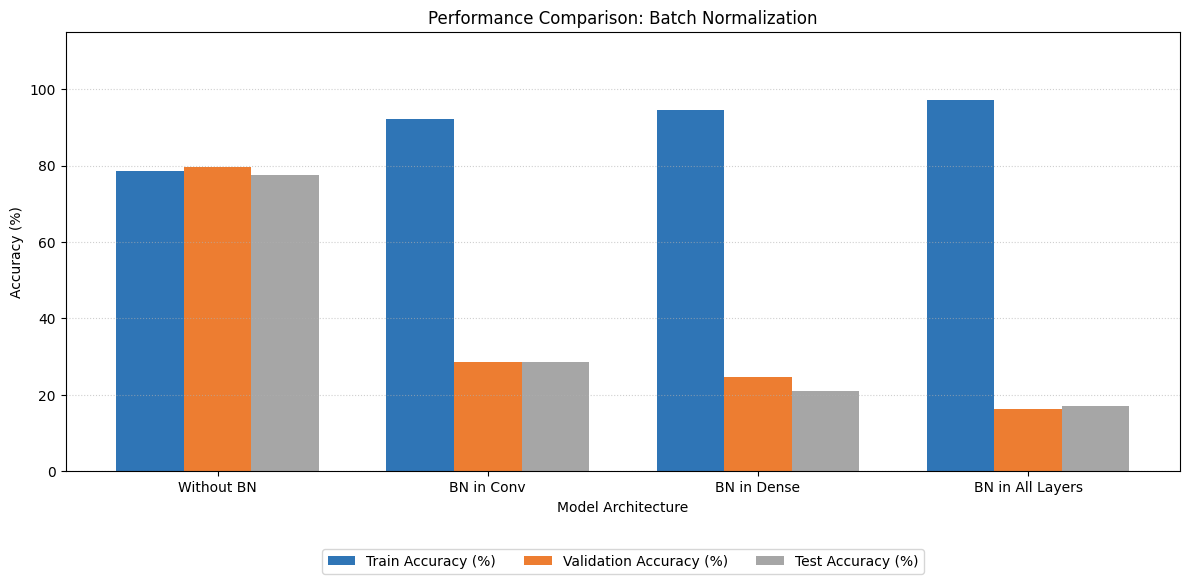

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report

# ----------------------------------------------------
# 1. Initialization and Dataset Preparation
# ----------------------------------------------------
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = 6
DATASET_DIR = '/content/dataset_split'

train_dir = os.path.join(DATASET_DIR, 'train')
val_dir = os.path.join(DATASET_DIR, 'val')
test_dir = os.path.join(DATASET_DIR, 'test')

# Load datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=True
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)

class_names = train_ds.class_names
print("Class Names:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

y_test_true = np.concatenate([y for x, y in test_ds], axis=0)

# ----------------------------------------------------
# 2. Model Builder with Batch Normalization Options
# ----------------------------------------------------
def build_bn_model(bn_conv=False, bn_dense=False):
    model = models.Sequential()
    model.add(layers.Rescaling(1./255, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)))

    conv_filters = [64, 128, 256]

    # Conv Blocks (64 -> 128 -> 256)
    for filters in conv_filters:
        if bn_conv:
            # Conv -> BatchNormalization -> Activation -> Pooling
            model.add(layers.Conv2D(filters, (3, 3), padding='same', use_bias=False))
            model.add(layers.BatchNormalization())
            model.add(layers.Activation('relu'))
        else:
            model.add(layers.Conv2D(filters, (3, 3), activation='relu', padding='same'))
        model.add(layers.MaxPooling2D((2, 2)))

    # Global Average Pooling
    model.add(layers.GlobalAveragePooling2D())

    # Dense 256 Layer
    if bn_dense:
        # Dense -> BatchNormalization -> Activation
        model.add(layers.Dense(256, use_bias=False))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation('relu'))
    else:
        model.add(layers.Dense(256, activation='relu'))

    # Output Layer
    model.add(layers.Dense(NUM_CLASSES, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# ----------------------------------------------------
# 3. Experiment Configuration and Execution
# ----------------------------------------------------
bn_experiments = {
    "Without BN": {"bn_conv": False, "bn_dense": False},
    "BN in Conv": {"bn_conv": True, "bn_dense": False},
    "BN in Dense": {"bn_conv": False, "bn_dense": True},
    "BN in All Layers": {"bn_conv": True, "bn_dense": True}
}

histories = {}
results_summary = []

for exp_name, config in bn_experiments.items():
    print(f"\n{'='*30} Running Experiment: {exp_name} {'='*30}")

    model = build_bn_model(bn_conv=config['bn_conv'], bn_dense=config['bn_dense'])
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )
    histories[exp_name] = history.history

    # Evaluation metrics
    train_acc = history.history['accuracy'][-1] * 100
    train_loss = history.history['loss'][-1]
    val_acc = history.history['val_accuracy'][-1] * 100
    val_loss = history.history['val_loss'][-1]
    test_loss, test_acc_raw = model.evaluate(test_ds, verbose=0)
    test_acc = test_acc_raw * 100

    # Predictions
    y_pred_probs = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # Scikit-learn Metrics
    f1_weighted = f1_score(y_test_true, y_pred, average='weighted', zero_division=0)
    p_weighted = precision_score(y_test_true, y_pred, average='weighted', zero_division=0)
    r_weighted = recall_score(y_test_true, y_pred, average='weighted', zero_division=0)
    f1_macro = f1_score(y_test_true, y_pred, average='macro', zero_division=0)

    # Format exactly aligned with target table structure
    results_summary.append({
        'Model architecture': f"CNN 3-Layers (64,128,256) + Dense 256 ({exp_name})",
        'Train Accuracy (%)': round(train_acc, 2),
        'Validation Accuracy (%)': round(val_acc, 2),
        'Test Accuracy (%)': round(test_acc, 2),
        'Train Loss': round(train_loss, 4),
        'Validation Loss': round(val_loss, 4),
        'F1 (Weighted)': round(f1_weighted, 4),
        # Additional Metrics
        'Precision (Weighted)': round(p_weighted, 4),
        'Recall (Weighted)': round(r_weighted, 4),
        'F1 (Macro)': round(f1_macro, 4)
    })

# ----------------------------------------------------
# 4. Results Summary Table and Excel Export
# ----------------------------------------------------
df_results = pd.DataFrame(results_summary)

target_columns = [
    'Model architecture',
    'Train Accuracy (%)',
    'Validation Accuracy (%)',
    'Test Accuracy (%)',
    'Train Loss',
    'Validation Loss',
    'F1 (Weighted)'
]

print("\n" + "="*90)
print("Experiment Results: Batch Normalization Comparison")
print("="*90)
print(df_results[target_columns].to_string(index=False))

output_path = '/content/batch_norm_experiment_results.xlsx'
df_results.to_excel(output_path, index=False)
print(f"\nResults successfully exported to: {output_path}")

# ----------------------------------------------------
# 5. Accuracy & Loss Comparison Bar Chart
# ----------------------------------------------------
x = np.arange(len(df_results['Model architecture']))
width = 0.25

plt.figure(figsize=(12, 6))
plt.bar(x - width, df_results['Train Accuracy (%)'], width, label='Train Accuracy (%)', color='#2F75B6')
plt.bar(x, df_results['Validation Accuracy (%)'], width, label='Validation Accuracy (%)', color='#ED7D31')
plt.bar(x + width, df_results['Test Accuracy (%)'], width, label='Test Accuracy (%)', color='#A6A6A6')

plt.xlabel('Model Architecture')
plt.ylabel('Accuracy (%)')
plt.title('Performance Comparison: Batch Normalization')
plt.xticks(x, list(bn_experiments.keys()))
plt.ylim(0, 115)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.25), ncol=3)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# เทียบระหว่าง flatten glob

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# ----------------------------------------------------
# 1. กำหนดค่าเริ่มต้นและเตรียม Dataset
# ----------------------------------------------------
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
EPOCHS = 10         # ปรับจำนวน Epoch ตามที่ต้องการ
NUM_CLASSES = 6
DATASET_DIR = '/content/dataset_split'

train_dir = os.path.join(DATASET_DIR, 'train')
val_dir = os.path.join(DATASET_DIR, 'val')
test_dir = os.path.join(DATASET_DIR, 'test')

# โหลดชุดข้อมูล
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=True
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)

class_names = train_ds.class_names
print("รายชื่อสายพันธุ์ข้าว:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Label จริงของ Test Set
y_test_true = np.concatenate([y for x, y in test_ds], axis=0)

# ----------------------------------------------------
# 2. ฟังก์ชันสร้างโมเดล
# ----------------------------------------------------
def build_cnn_model(dense_units):
    model = models.Sequential([
        layers.Rescaling(1./255, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

        # Conv Block 1
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 3
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(dense_units, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# ----------------------------------------------------
# 3. รันการทดลองพร้อมคำนวณ Parameters และ Metrics ทั้งหมด
# ----------------------------------------------------
dense_experiments = [64, 128, 256, 512]
histories = {}
results_summary = []

for units in dense_experiments:
    exp_name = f"Dense{units}"
    print(f"\n{'='*30} กำลังทดลอง: {exp_name} {'='*30}")

    model = build_cnn_model(units)

    # คำนวณจำนวน Parameter ของโมเดล
    total_params = model.count_params()
    trainable_params = int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))
    print(f"Total Parameters: {total_params:,} | Trainable Parameters: {trainable_params:,}")

    # เทรนโมเดล
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )
    histories[exp_name] = history.history

    # ดึงค่าผลลัพธ์ Train และ Val
    train_acc = history.history['accuracy'][-1]
    train_loss = history.history['loss'][-1]
    val_acc = history.history['val_accuracy'][-1]
    val_loss = history.history['val_loss'][-1]

    # ประเมินบน Test Set
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    # ทำนายผลบน Test Set เพื่อคำนวณ Precision, Recall, F1
    y_pred_probs = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # คำนวณ Metrics ด้วย scikit-learn
    p_macro = precision_score(y_test_true, y_pred, average='macro', zero_division=0)
    r_macro = recall_score(y_test_true, y_pred, average='macro', zero_division=0)
    f1_macro = f1_score(y_test_true, y_pred, average='macro', zero_division=0)

    p_weighted = precision_score(y_test_true, y_pred, average='weighted', zero_division=0)
    r_weighted = recall_score(y_test_true, y_pred, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_test_true, y_pred, average='weighted', zero_division=0)

    # บันทึกข้อมูลสรุปทั้งหมดลงตาราง
    results_summary.append({
        'Model': exp_name,
        'Total Params': total_params,
        'Trainable Params': trainable_params,
        'Train Acc': round(train_acc, 4),
        'Train Loss': round(train_loss, 4),
        'Val Acc': round(val_acc, 4),
        'Val Loss': round(val_loss, 4),
        'Test Acc': round(test_acc, 4),
        'Test Loss': round(test_loss, 4),
        'Precision (Macro)': round(p_macro, 4),
        'Recall (Macro)': round(r_macro, 4),
        'F1 (Macro)': round(f1_macro, 4),
        'Precision (Weighted)': round(p_weighted, 4),
        'Recall (Weighted)': round(r_weighted, 4),
        'F1 (Weighted)': round(f1_weighted, 4)
    })

    # Classification Report
    print(f"\nClassification Report for {exp_name}:")
    print(classification_report(y_test_true, y_pred, target_names=class_names, digits=4, zero_division=0))

    # Confusion Matrix
    cm = confusion_matrix(y_test_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {exp_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# ----------------------------------------------------
# 4. สรุปผลลัพธ์เป็น DataFrame และ Export ออก Excel
# ----------------------------------------------------
df_results = pd.DataFrame(results_summary)
print("\n" + "="*80)
print("ตารางสรุปผลการทดลองทั้งหมด (รวม Parameters)")
print("="*80)
display(df_results)

# บันทึกไฟล์ Excel
df_results.to_excel('/content/experiment_results_with_params.xlsx', index=False)
print("บันทึกไฟล์เรียบร้อยที่: /content/experiment_results_with_params.xlsx")

# ----------------------------------------------------
# 5. พล็อตภาพกราฟการเรียนรู้และแผนภูมิผลการทดลอง
# ----------------------------------------------------
# 5.1 กราฟ Accuracy & Loss Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for name, hist in histories.items():
    ax1.plot(hist['accuracy'], label=f'{name} - Train')
    ax1.plot(hist['val_accuracy'], linestyle='--', label=f'{name} - Val')

    ax2.plot(hist['loss'], label=f'{name} - Train')
    ax2.plot(hist['val_loss'], linestyle='--', label=f'{name} - Val')

ax1.set_title('Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right', fontsize='small')
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.set_title('Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(loc='upper right', fontsize='small')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.suptitle('ภาพที่ 4-1 กราฟการเรียนรู้ CNN', y=0.01)
plt.tight_layout()
plt.show()

# 5.2 แผนภูมิแท่งเปรียบเทียบผลการทดลอง
x = np.arange(len(df_results['Model']))
width = 0.25

plt.figure(figsize=(9, 6))
plt.bar(x - width, df_results['Train Acc'], width, label='Train Accuracy', color='#2F75B6')
plt.bar(x, df_results['Val Acc'], width, label='Validation Accuracy', color='#ED7D31')
plt.bar(x + width, df_results['Test Acc'], width, label='Test Accuracy', color='#A6A6A6')

plt.xlabel('โมเดล')
plt.ylabel('Accuracy')
plt.title('CNN')
plt.xticks(x, df_results['Model'])
plt.ylim(0, 1.2)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.suptitle('ภาพที่ 4-2 แผนภูมิผลการทดลอง CNN', y=-0.05)
plt.show()

แบบบันทึก model tfite

Found 1437 files belonging to 6 classes.
Found 178 files belonging to 6 classes.
Found 182 files belonging to 6 classes.
Class names: ['R1', 'R2', 'R3', 'R4', 'R5', 'R6']

============================== Running Experiment: Dense32 ==============================
Total Parameters: 1,142,054 | Trainable Parameters: 1,142,054
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 9s 107ms/step - accuracy: 0.2888 - loss: 1.6770 - val_accuracy: 0.5281 - val_loss: 1.3754
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.4753 - loss: 1.3089 - val_accuracy: 0.6404 - val_loss: 0.9766
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6006 - loss: 1.0504 - val_accuracy: 0.7640 - val_loss: 0.6998
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7209 - loss: 0.7963 - val_accuracy: 0.8483 - val_loss: 0.4981
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7530 - loss: 0.6718 - val_accuracy: 0.8539 - val_loss: 0.4451
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7523 - loss: 0.6291 - val_accuracy: 0.8876 - val_loss: 0.3588
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7620 - loss: 0.5746 - val_accuracy: 0.8876 - val_loss: 0.3910
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7878 - loss: 0.5133 - val_accuracy: 0.9270 - val_loss: 0

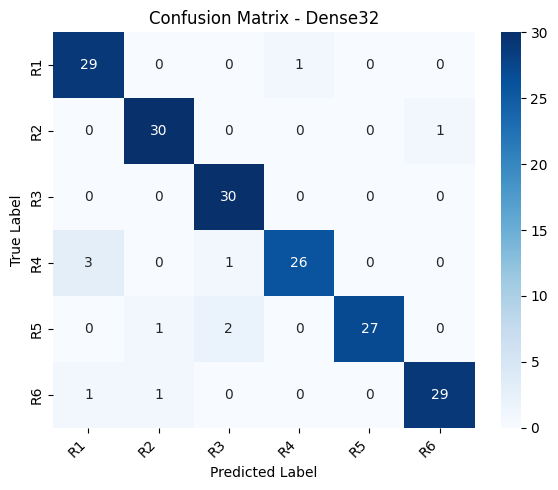


============================== Running Experiment: Dense64 ==============================
Total Parameters: 2,190,854 | Trainable Parameters: 2,190,854
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 93ms/step - accuracy: 0.3695 - loss: 1.5522 - val_accuracy: 0.6517 - val_loss: 1.0279
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.6576 - loss: 0.9237 - val_accuracy: 0.7865 - val_loss: 0.6556
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7523 - loss: 0.6655 - val_accuracy: 0.7303 - val_loss: 0.7234
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.7919 - loss: 0.5548 - val_accuracy: 0.8708 - val_loss: 0.4084
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8629 - loss: 0.3803 - val_accuracy: 0.8483 - val_loss: 0.3763
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8671 - loss: 0.3665 - val_accuracy: 0.8652 - val_loss: 0.3383
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8824 - loss: 0.2936 - val_accuracy: 0.8876 - val_loss: 0.2812
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8907 - loss: 0.2820 - val_accuracy: 0.9045 - val_loss: 0.

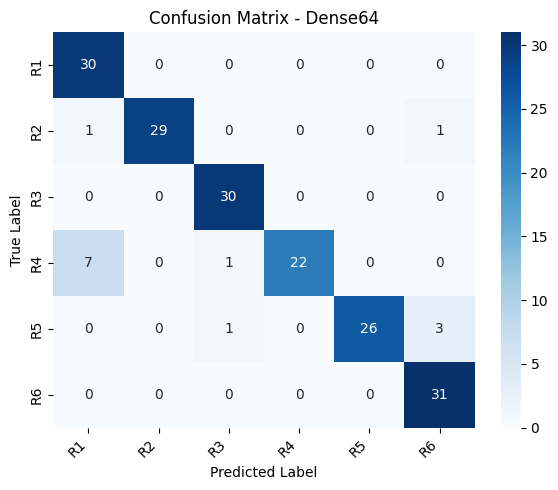


============================== Running Experiment: Dense128 ==============================
Total Parameters: 4,288,454 | Trainable Parameters: 4,288,454
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 96ms/step - accuracy: 0.4363 - loss: 1.4007 - val_accuracy: 0.7191 - val_loss: 0.8897
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.7460 - loss: 0.6989 - val_accuracy: 0.8146 - val_loss: 0.5395
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8219 - loss: 0.4921 - val_accuracy: 0.8371 - val_loss: 0.4861
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8657 - loss: 0.3747 - val_accuracy: 0.8933 - val_loss: 0.3717
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8956 - loss: 0.2722 - val_accuracy: 0.8708 - val_loss: 0.3161
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9193 - loss: 0.2216 - val_accuracy: 0.9326 - val_loss: 0.2452
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9485 - loss: 0.1605 - val_accuracy: 0.8989 - val_loss: 0.2283
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9457 - loss: 0.1361 - val_accuracy: 0.9438 - val_loss: 0.

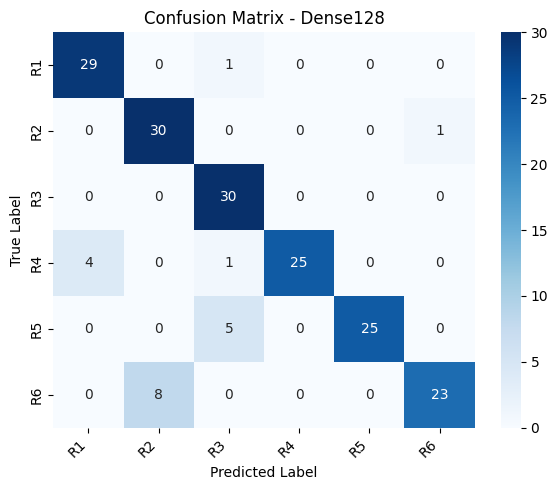


============================== Running Experiment: Dense256 ==============================
Total Parameters: 8,483,654 | Trainable Parameters: 8,483,654
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 105ms/step - accuracy: 0.4774 - loss: 1.2807 - val_accuracy: 0.7247 - val_loss: 0.8157
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.7836 - loss: 0.5826 - val_accuracy: 0.7753 - val_loss: 0.7039
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8344 - loss: 0.4502 - val_accuracy: 0.8315 - val_loss: 0.4619
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8852 - loss: 0.2994 - val_accuracy: 0.8820 - val_loss: 0.3654
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9207 - loss: 0.2281 - val_accuracy: 0.8764 - val_loss: 0.3326
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9388 - loss: 0.1597 - val_accuracy: 0.9270 - val_loss: 0.1975
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9471 - loss: 0.1493 - val_accuracy: 0.9438 - val_loss: 0.1856
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9666 - loss: 0.0966 - val_accuracy: 0.9438 - val_loss: 0

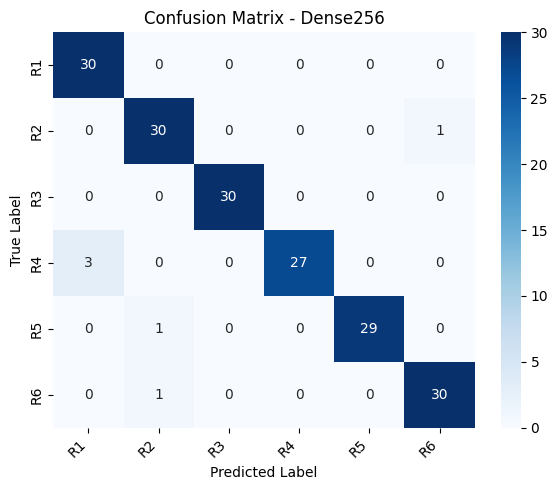


============================== Running Experiment: Dense512 ==============================
Total Parameters: 16,874,054 | Trainable Parameters: 16,874,054
Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 9s 106ms/step - accuracy: 0.4356 - loss: 1.3992 - val_accuracy: 0.5899 - val_loss: 0.9547
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.7189 - loss: 0.7198 - val_accuracy: 0.7865 - val_loss: 0.5993
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.8511 - loss: 0.4144 - val_accuracy: 0.8090 - val_loss: 0.5228
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8935 - loss: 0.2759 - val_accuracy: 0.8876 - val_loss: 0.3410
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.9360 - loss: 0.1959 - val_accuracy: 0.8427 - val_loss: 0.3405
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9262 - loss: 0.2057 - val_accuracy: 0.9213 - val_loss: 0.2560
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9603 - loss: 0.1083 - val_accuracy: 0.9551 - val_loss: 0.1551
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9638 - loss: 0.0969 - val_accuracy: 0.9270 - val_loss: 0

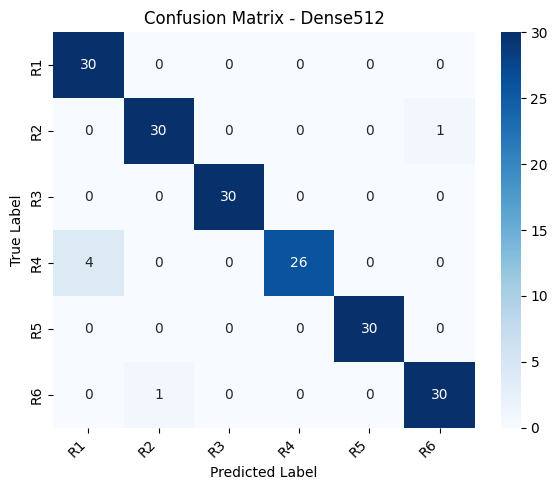


Best Model: Dense256 (Test Accuracy: 0.9670)
Saved Keras model: /content/best_model_Dense256.keras
Saved artifact at '/tmp/tmpglva3zu_'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='input_layer_8')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  140182437225552: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140182437216528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140182437218448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140178007485968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140178007485008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140178007480784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140178007482512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140178007484624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140178007476176: TensorSpec(shape=(), dtype=tf.resour

,Model,Dense Units,Total Params,Trainable Params,Train Acc,Train Loss,Val Acc,Val Loss,Test Acc,Test Loss,Precision (Macro),Recall (Macro),F1 (Macro),Precision (Weighted),Recall (Weighted),F1 (Weighted)
0,Dense32,32,1142054,1142054,0.8156,0.4446,0.9382,0.2646,0.9396,0.8031,0.9425,0.9394,0.9393,0.9426,0.9396,0.9394
1,Dense64,64,2190854,2190854,0.9074,0.2290,0.9157,0.2305,0.9231,1.2371,0.9354,0.9226,0.9218,0.9355,0.9231,0.9222
2,Dense128,128,4288454,4288454,0.9631,0.1057,0.8539,0.3958,0.8901,0.9675,0.9062,0.8905,0.8900,0.9059,0.8901,0.8896
3,Dense256,256,8483654,8483654,0.9589,0.1225,0.9719,0.1119,0.9670,0.9057,0.9691,0.9670,0.9672,0.9689,0.9670,0.9671
4,Dense512,512,16874054,16874054,0.9729,0.0732,0.9775,0.1289,0.9670,0.7472,0.9696,0.9670,0.9669,0.9696,0.9670,0.9669


Saved summary report to: /content/cnn_dense_experiments_results.xlsx


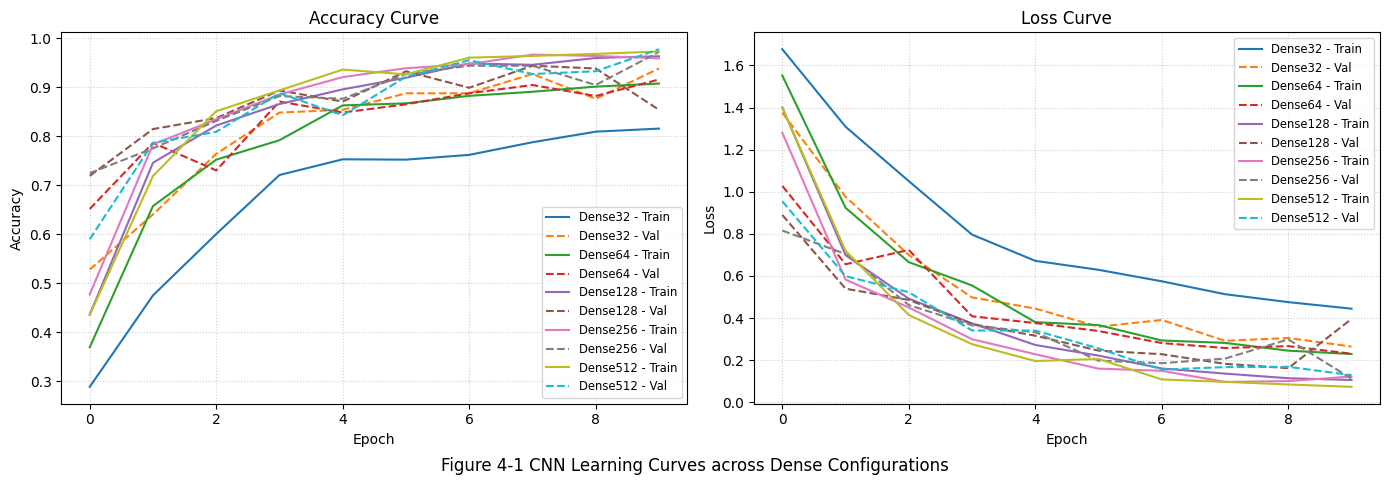

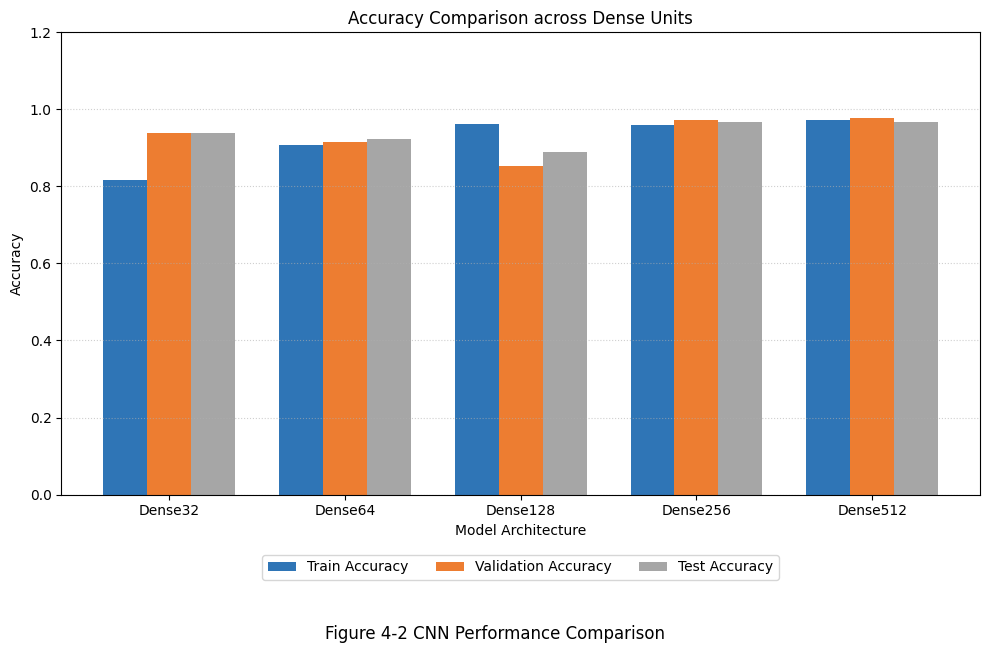

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# ----------------------------------------------------
# 1. Configuration & Dataset Preparation
# ----------------------------------------------------
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = 6
DATASET_DIR = '/content/dataset_split'

train_dir = os.path.join(DATASET_DIR, 'train')
val_dir = os.path.join(DATASET_DIR, 'val')
test_dir = os.path.join(DATASET_DIR, 'test')

# Load datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=True
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)

class_names = train_ds.class_names
print("Class names:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Ground truth labels for Test Set
y_test_true = np.concatenate([y for x, y in test_ds], axis=0)

# ----------------------------------------------------
# 2. CNN Model Builder (Flatten + Dense)
# ----------------------------------------------------
def build_cnn_model(dense_units):
    model = models.Sequential([
        layers.Rescaling(1./255, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

        # Conv Block 1
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 3
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Flatten & Dense
        layers.Flatten(),
        layers.Dense(dense_units, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# ----------------------------------------------------
# 3. Run Experiments (Dense: 32, 64, 128, 256, 512)
# ----------------------------------------------------
dense_experiments = [32, 64, 128, 256, 512]
histories = {}
results_summary = []

best_model = None
best_test_acc = -1.0
best_model_name = ""

for units in dense_experiments:
    exp_name = f"Dense{units}"
    print(f"\n{'='*30} Running Experiment: {exp_name} {'='*30}")

    model = build_cnn_model(units)

    # Calculate model parameters
    total_params = model.count_params()
    trainable_params = int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))
    print(f"Total Parameters: {total_params:,} | Trainable Parameters: {trainable_params:,}")

    # Train model
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )
    histories[exp_name] = history.history

    # Final epoch train & validation metrics
    train_acc = history.history['accuracy'][-1]
    train_loss = history.history['loss'][-1]
    val_acc = history.history['val_accuracy'][-1]
    val_loss = history.history['val_loss'][-1]

    # Evaluate on test set
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    # Track the best model based on Test Accuracy
    if test_acc > best_test_acc:
        best_test_acc = test_acc
        best_model = tf.keras.models.clone_model(model)
        best_model.set_weights(model.get_weights())
        best_model_name = exp_name

    # Predictions for evaluation metrics
    y_pred_probs = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # Precision, Recall, F1-Score
    p_macro = precision_score(y_test_true, y_pred, average='macro', zero_division=0)
    r_macro = recall_score(y_test_true, y_pred, average='macro', zero_division=0)
    f1_macro = f1_score(y_test_true, y_pred, average='macro', zero_division=0)

    p_weighted = precision_score(y_test_true, y_pred, average='weighted', zero_division=0)
    r_weighted = recall_score(y_test_true, y_pred, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_test_true, y_pred, average='weighted', zero_division=0)

    results_summary.append({
        'Model': exp_name,
        'Dense Units': units,
        'Total Params': total_params,
        'Trainable Params': trainable_params,
        'Train Acc': round(train_acc, 4),
        'Train Loss': round(train_loss, 4),
        'Val Acc': round(val_acc, 4),
        'Val Loss': round(val_loss, 4),
        'Test Acc': round(test_acc, 4),
        'Test Loss': round(test_loss, 4),
        'Precision (Macro)': round(p_macro, 4),
        'Recall (Macro)': round(r_macro, 4),
        'F1 (Macro)': round(f1_macro, 4),
        'Precision (Weighted)': round(p_weighted, 4),
        'Recall (Weighted)': round(r_weighted, 4),
        'F1 (Weighted)': round(f1_weighted, 4)
    })

    # Classification Report
    print(f"\nClassification Report - {exp_name}:")
    print(classification_report(y_test_true, y_pred, target_names=class_names, digits=4, zero_division=0))

    # Confusion Matrix Plot (English labels)
    cm = confusion_matrix(y_test_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {exp_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

# ----------------------------------------------------
# 4. Save Best Model (.keras and .tflite)
# ----------------------------------------------------
print("\n" + "="*80)
print(f"Best Model: {best_model_name} (Test Accuracy: {best_test_acc:.4f})")

# 4.1 Save as Keras (.keras)
keras_filename = f'/content/best_model_{best_model_name}.keras'
best_model.save(keras_filename)
print(f"Saved Keras model: {keras_filename}")

# 4.2 Save as TFLite (.tflite)
converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
tflite_model_bytes = converter.convert()

tflite_filename = f'/content/best_model_{best_model_name}.tflite'
with open(tflite_filename, 'wb') as f:
    f.write(tflite_model_bytes)
print(f"Saved TFLite model: {tflite_filename}")
print("="*80)

# ----------------------------------------------------
# 5. Export Summary Table to Excel
# ----------------------------------------------------
df_results = pd.DataFrame(results_summary)
print("\nSummary Table:")
display(df_results)

excel_filename = '/content/cnn_dense_experiments_results.xlsx'
df_results.to_excel(excel_filename, index=False)
print(f"Saved summary report to: {excel_filename}")

# ----------------------------------------------------
# 6. Plot Learning Curves & Comparison Chart (English Only)
# ----------------------------------------------------
# 6.1 Training & Validation Curves (Accuracy and Loss)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for name, hist in histories.items():
    ax1.plot(hist['accuracy'], label=f'{name} - Train')
    ax1.plot(hist['val_accuracy'], linestyle='--', label=f'{name} - Val')

    ax2.plot(hist['loss'], label=f'{name} - Train')
    ax2.plot(hist['val_loss'], linestyle='--', label=f'{name} - Val')

ax1.set_title('Accuracy Curve')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right', fontsize='small')
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.set_title('Loss Curve')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(loc='upper right', fontsize='small')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Figure 4-1 CNN Learning Curves across Dense Configurations', y=0.01)
plt.tight_layout()
plt.show()

# 6.2 Bar Chart Comparison
x = np.arange(len(df_results['Model']))
width = 0.25

plt.figure(figsize=(10, 6))
plt.bar(x - width, df_results['Train Acc'], width, label='Train Accuracy', color='#2F75B6')
plt.bar(x, df_results['Val Acc'], width, label='Validation Accuracy', color='#ED7D31')
plt.bar(x + width, df_results['Test Acc'], width, label='Test Accuracy', color='#A6A6A6')

plt.xlabel('Model Architecture')
plt.ylabel('Accuracy')
plt.title('Accuracy Comparison across Dense Units')
plt.xticks(x, df_results['Model'])
plt.ylim(0, 1.2)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.suptitle('Figure 4-2 CNN Performance Comparison', y=-0.05)
plt.show()

ทดลอง dropout

Found 1437 files belonging to 6 classes.
Found 178 files belonging to 6 classes.
Found 182 files belonging to 6 classes.
Class Names: ['R1', 'R2', 'R3', 'R4', 'R5', 'R6']

Running Experiment: Flatten_Drop0.1
Pooling: FLATTEN | Dropout: 0.1


/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Total Parameters: 8,483,654 | Trainable Parameters: 8,483,654
Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 16s 176ms/step - accuracy: 0.4363 - loss: 1.3574 - val_accuracy: 0.5955 - val_loss: 0.9548
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.7683 - loss: 0.6442 - val_accuracy: 0.8034 - val_loss: 0.5366
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8838 - loss: 0.3342 - val_accuracy: 0.8708 - val_loss: 0.4040
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9061 - loss: 0.2638 - val_accuracy: 0.8989 - val_loss: 0.2890
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9388 - loss: 0.1830 - val_accuracy: 0.8034 - val_loss: 0.4939
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9402 - loss: 0.1657 - val_accuracy: 0.8989 - val_loss: 0.2393
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9631 - loss: 0.1037 - val_accuracy: 0.9494 - val_loss: 0.1913
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/s

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 85ms/step - accuracy: 0.4245 - loss: 1.4116 - val_accuracy: 0.7416 - val_loss: 0.8905
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7439 - loss: 0.7096 - val_accuracy: 0.7640 - val_loss: 0.6857
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8615 - loss: 0.3759 - val_accuracy: 0.8596 - val_loss: 0.4174
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9019 - loss: 0.2727 - val_accuracy: 0.8258 - val_loss: 0.4040
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9179 - loss: 0.2291 - val_accuracy: 0.8933 - val_loss: 0.2892
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9123 - loss: 0.2172 - val_accuracy: 0.8820 - val_loss: 0.2862
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.9478 - loss: 0.1451 - val_accuracy: 0.9270 - val_loss: 0.2217
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9603 - loss: 0.1014 - val_accuracy: 0.9551 - val_loss: 0.

...

45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 88ms/step - accuracy: 0.1684 - loss: 1.7916 - val_accuracy: 0.3596 - val_loss: 1.7845
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.1879 - loss: 1.7785 - val_accuracy: 0.3989 - val_loss: 1.7521
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.3062 - loss: 1.6726 - val_accuracy: 0.3596 - val_loss: 1.5697
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.4231 - loss: 1.4936 - val_accuracy: 0.4438 - val_loss: 1.3628
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.5268 - loss: 1.2858 - val_accuracy: 0.5843 - val_loss: 1.2199
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.5692 - loss: 1.1505 - val_accuracy: 0.6236 - val_loss: 1.0434
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6688 - loss: 0.9416 - val_accuracy: 0.6573 - val_loss: 0.9214
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6980 - loss: 0.8323 - val_accuracy: 0.6910 - val_loss: 0.

/usr/local/lib/python3.13/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 83ms/step - accuracy: 0.1573 - loss: 1.7939 - val_accuracy: 0.1966 - val_loss: 1.7898
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.1872 - loss: 1.7825 - val_accuracy: 0.2135 - val_loss: 1.7639
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.2846 - loss: 1.6660 - val_accuracy: 0.3315 - val_loss: 1.5325
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.3500 - loss: 1.5804 - val_accuracy: 0.3315 - val_loss: 1.5188
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.4433 - loss: 1.4626 - val_accuracy: 0.4719 - val_loss: 1.3830
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.5936 - loss: 1.1429 - val_accuracy: 0.6404 - val_loss: 1.0056
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6583 - loss: 0.9555 - val_accuracy: 0.7360 - val_loss: 0.8364
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6806 - loss: 0.8837 - val_accuracy: 0.7472 - val_loss: 0.

,Model Name,Structure,Dropout Rate,Total Params,Trainable Params,Train Acc,Train Loss,Val Acc,Val Loss,Test Acc,Test Loss,Precision (Macro),Recall (Macro),F1 Score (Macro)
0,Flatten_Drop0.1,Flatten,0.1,"8,483,654","8,483,654",0.9770,0.0517,0.9551,0.1648,0.9286,0.9002,0.9406,0.9290,0.9303
1,Flatten_Drop0.2,Flatten,0.2,"8,483,654","8,483,654",0.9889,0.0435,0.9888,0.0706,0.9780,0.7571,0.9792,0.9783,0.9783
2,Flatten_Drop0.3,Flatten,0.3,"8,483,654","8,483,654",0.9715,0.0836,0.9775,0.0637,0.9670,0.7198,0.9677,0.9672,0.9670
3,GAP_Drop0.1,GAP,0.1,"127,814","127,814",0.6938,0.8124,0.7303,0.8024,0.7473,1.1001,0.7868,0.7473,0.7484
4,GAP_Drop0.2,GAP,0.2,"127,814","127,814",0.7314,0.7318,0.7753,0.6736,0.7308,0.8772,0.7466,0.7301,0.7191
5,GAP_Drop0.3,GAP,0.3,"127,814","127,814",0.7404,0.7302,0.7247,0.7742,0.7033,0.9931,0.7324,0.7023,0.6993



Saved summary table to: /content/dropout_experiment_results.xlsx


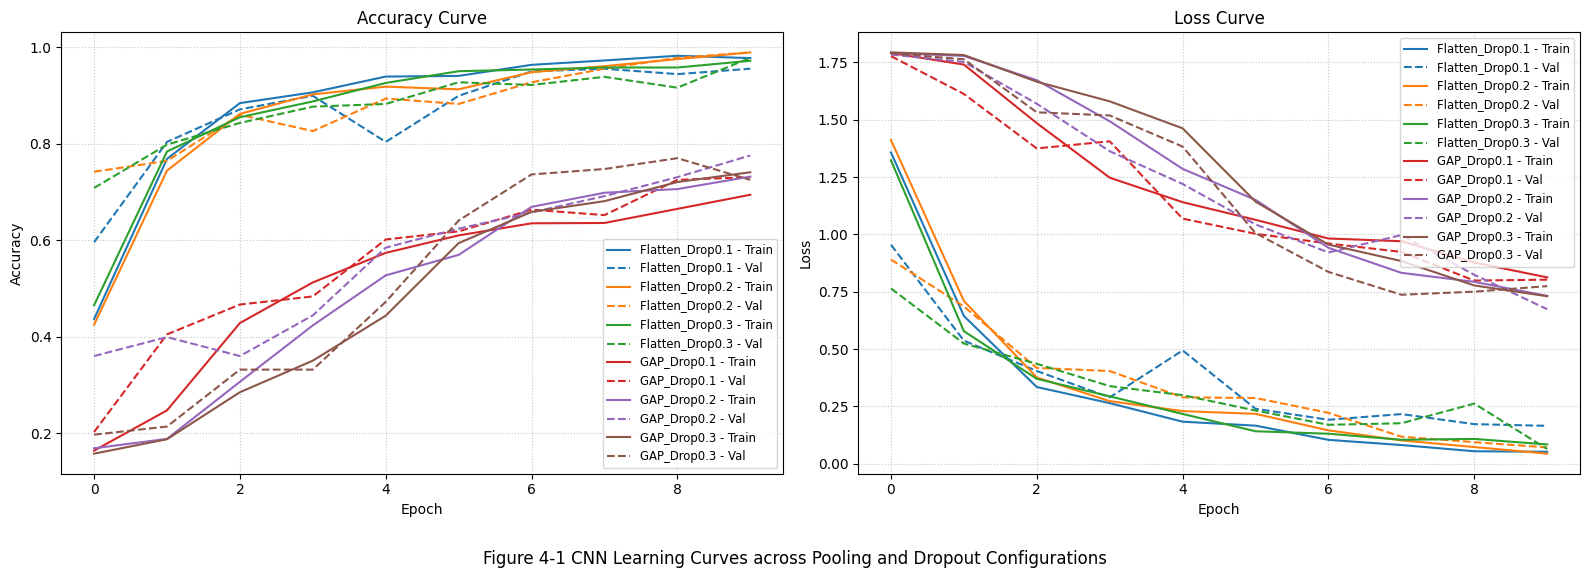

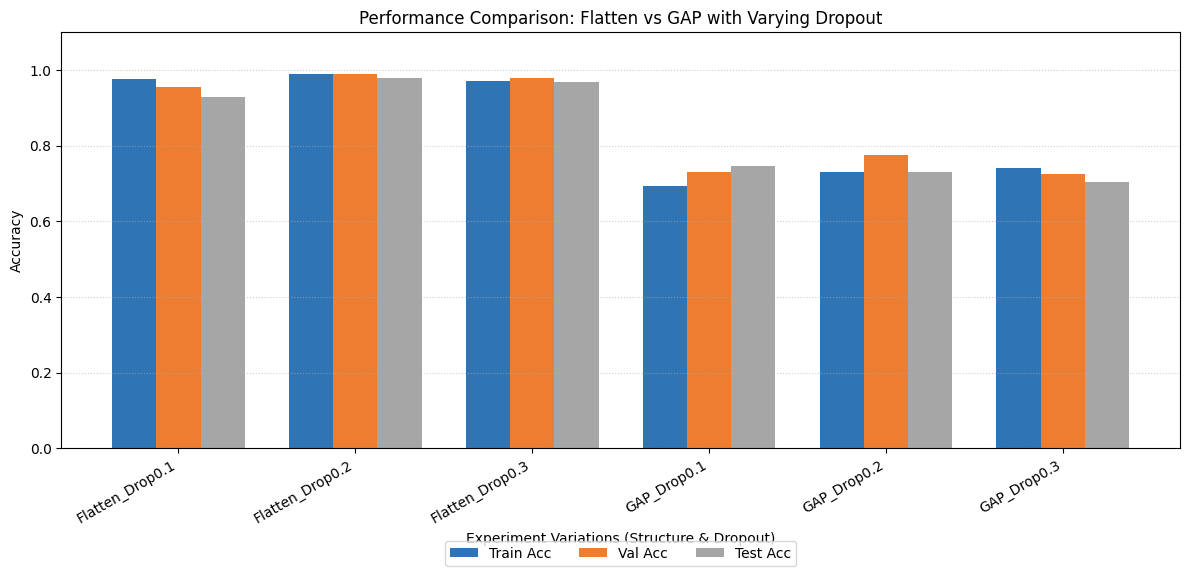

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# ----------------------------------------------------
# 1. Dataset Configuration & Preparation
# ----------------------------------------------------
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = 6
DATASET_DIR = '/content/dataset_split'

train_dir = os.path.join(DATASET_DIR, 'train')
val_dir = os.path.join(DATASET_DIR, 'val')
test_dir = os.path.join(DATASET_DIR, 'test')

# Load datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=True
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)

class_names = train_ds.class_names
print("Class Names:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Ground truth labels for Test Set
y_test_true = np.concatenate([y for x, y in test_ds], axis=0)

# ----------------------------------------------------
# 2. Model Builder Function (Filters: 32 -> 64 -> 128)
# ----------------------------------------------------
def build_experiment_model(pooling_type='flatten', dense_units=256, dropout_rate=0.3):
    model = models.Sequential()
    model.add(layers.Rescaling(1./255, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)))

    # Conv Block 1 (Filters: 32)
    model.add(layers.Conv2D(32, (3, 3), activation='relu', padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))

    # Conv Block 2 (Filters: 64)
    model.add(layers.Conv2D(64, (3, 3), activation='relu', padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))

    # Conv Block 3 (Filters: 128)
    model.add(layers.Conv2D(128, (3, 3), activation='relu', padding='same'))
    model.add(layers.MaxPooling2D((2, 2)))

    # Dimensionality Reduction Strategy
    if pooling_type.lower() == 'flatten':
        model.add(layers.Flatten())
    elif pooling_type.lower() == 'gap':
        model.add(layers.GlobalAveragePooling2D())
    else:
        raise ValueError("Specify 'flatten' or 'gap'")

    # Dense Classifier + Dropout
    model.add(layers.Dense(dense_units, activation='relu'))
    if dropout_rate > 0.0:
        model.add(layers.Dropout(dropout_rate))
    model.add(layers.Dense(NUM_CLASSES, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

# ----------------------------------------------------
# 3. Setup Experiment Configurations (6 Models)
# ----------------------------------------------------
experiment_configs = [
    {'name': 'Flatten_Drop0.1', 'type': 'flatten', 'dropout': 0.1},
    {'name': 'Flatten_Drop0.2', 'type': 'flatten', 'dropout': 0.2},
    {'name': 'Flatten_Drop0.3', 'type': 'flatten', 'dropout': 0.3},
    {'name': 'GAP_Drop0.1',     'type': 'gap',     'dropout': 0.1},
    {'name': 'GAP_Drop0.2',     'type': 'gap',     'dropout': 0.2},
    {'name': 'GAP_Drop0.3',     'type': 'gap',     'dropout': 0.3}
]

histories = {}
results_summary = []

# สร้างโฟลเดอร์เก็บโมเดล
os.makedirs('/content/saved_models', exist_ok=True)

# ----------------------------------------------------
# 4. Run Experiments & Save Models
# ----------------------------------------------------
for cfg in experiment_configs:
    exp_name = cfg['name']
    pool_type = cfg['type']
    drop_rate = cfg['dropout']

    print(f"\n{'='*40}")
    print(f"Running Experiment: {exp_name}")
    print(f"Pooling: {pool_type.upper()} | Dropout: {drop_rate}")
    print(f"{'='*40}")

    # สร้างและคำนวณ Parameters
    model = build_experiment_model(pooling_type=pool_type, dense_units=256, dropout_rate=drop_rate)
    total_params = model.count_params()
    trainable_params = int(np.sum([tf.keras.backend.count_params(w) for w in model.trainable_weights]))
    print(f"Total Parameters: {total_params:,} | Trainable Parameters: {trainable_params:,}")

    # เทรนโมเดล
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )
    histories[exp_name] = history.history

    # ค่าผลลัพธ์รอบสุดท้าย
    train_acc = history.history['accuracy'][-1]
    train_loss = history.history['loss'][-1]
    val_acc = history.history['val_accuracy'][-1]
    val_loss = history.history['val_loss'][-1]

    # ประเมินผลบน Test Set
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    # คำนวณ Metrics เพิ่มเติม
    y_pred_probs = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    p_macro = precision_score(y_test_true, y_pred, average='macro', zero_division=0)
    r_macro = recall_score(y_test_true, y_pred, average='macro', zero_division=0)
    f1_macro = f1_score(y_test_true, y_pred, average='macro', zero_division=0)

    # บันทึกข้อมูลสรุป
    results_summary.append({
        'Model Name': exp_name,
        'Structure': 'Flatten' if pool_type == 'flatten' else 'GAP',
        'Dropout Rate': drop_rate,
        'Total Params': f"{total_params:,}",
        'Trainable Params': f"{trainable_params:,}",
        'Train Acc': round(train_acc, 4),
        'Train Loss': round(train_loss, 4),
        'Val Acc': round(val_acc, 4),
        'Val Loss': round(val_loss, 4),
        'Test Acc': round(test_acc, 4),
        'Test Loss': round(test_loss, 4),
        'Precision (Macro)': round(p_macro, 4),
        'Recall (Macro)': round(r_macro, 4),
        'F1 Score (Macro)': round(f1_macro, 4)
    })

    # Save Keras & TFLite models
    keras_path = f"/content/saved_models/model_{exp_name}.keras"
    model.save(keras_path)

    tflite_path = f"/content/saved_models/model_{exp_name}.tflite"
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    tflite_model_bytes = converter.convert()
    with open(tflite_path, 'wb') as f:
        f.write(tflite_model_bytes)
    print(f"-> Saved: {keras_path} and {tflite_path}")

# ----------------------------------------------------
# 5. Export Summary to Excel
# ----------------------------------------------------
df_results = pd.DataFrame(results_summary)
print("\n" + "="*80)
print("EXPERIMENT RESULTS SUMMARY")
print("="*80)
display(df_results)

excel_filename = '/content/dropout_experiment_results.xlsx'
df_results.to_excel(excel_filename, index=False)
print(f"\nSaved summary table to: {excel_filename}")

# ----------------------------------------------------
# 6. Plot Visualizations (Learning Curves & Bar Chart)
# ----------------------------------------------------

# --- 6.1 Learning Curves (Accuracy & Loss) ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
colors = plt.cm.tab10.colors[:len(histories)]

for (name, hist), color in zip(histories.items(), colors):
    # Accuracy Plot (Train: solid line, Val: dashed line)
    ax1.plot(hist['accuracy'], label=f'{name} - Train', color=color, linestyle='-')
    ax1.plot(hist['val_accuracy'], label=f'{name} - Val', color=color, linestyle='--')

    # Loss Plot (Train: solid line, Val: dashed line)
    ax2.plot(hist['loss'], label=f'{name} - Train', color=color, linestyle='-')
    ax2.plot(hist['val_loss'], label=f'{name} - Val', color=color, linestyle='--')

ax1.set_title('Accuracy Curve')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right', fontsize='small')
ax1.grid(True, linestyle=':', alpha=0.7)

ax2.set_title('Loss Curve')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(loc='upper right', fontsize='small')
ax2.grid(True, linestyle=':', alpha=0.7)

plt.suptitle('Figure 4-1 CNN Learning Curves across Pooling and Dropout Configurations', y=0.02, fontsize=12)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

# --- 6.2 Accuracy Comparison Bar Chart ---
x = np.arange(len(df_results['Model Name']))
width = 0.25

plt.figure(figsize=(12, 6))
plt.bar(x - width, df_results['Train Acc'], width, label='Train Acc', color='#2F75B6')
plt.bar(x, df_results['Val Acc'], width, label='Val Acc', color='#ED7D31')
plt.bar(x + width, df_results['Test Acc'], width, label='Test Acc', color='#A6A6A6')

plt.xlabel('Experiment Variations (Structure & Dropout)')
plt.ylabel('Accuracy')
plt.title('Performance Comparison: Flatten vs GAP with Varying Dropout')
plt.xticks(x, df_results['Model Name'], rotation=30, ha='right')
plt.ylim(0, 1.1)
plt.legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), ncol=3)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

Found 1437 files belonging to 6 classes.
Found 178 files belonging to 6 classes.
Found 182 files belonging to 6 classes.
Class Names: ['R1', 'R2', 'R3', 'R4', 'R5', 'R6']
Number of Classes: 6

Dataset preparation completed.
Test samples: 182

Experiment 1/6
Model: Flatten_32-64-128_Drop0.1
Pooling: FLATTEN
Dropout: 0.1
Total Parameters: 8,483,654
Trainable Parameters: 8,483,654


Model: "CNN_flatten"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,483,654 (32.36 MB)

 Trainable params: 8,483,654 (32.36 MB)

...

 Trainable params: 438,150 (1.67 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 103ms/step - accuracy: 0.1566 - loss: 1.7896 - val_accuracy: 0.1685 - val_loss: 1.7804
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.1997 - loss: 1.7775 - val_accuracy: 0.2022 - val_loss: 1.7600
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.3466 - loss: 1.5886 - val_accuracy: 0.3764 - val_loss: 1.5341
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.5170 - loss: 1.3040 - val_accuracy: 0.4719 - val_loss: 1.4487
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.5936 - loss: 1.1098 - val_accuracy: 0.7079 - val_loss: 0.9257
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.6347 - loss: 0.9736 - val_accuracy: 0.6011 - val_loss: 0.9512
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.6875 - loss: 0.8495 - val_accuracy: 0.6685 - val_loss: 0.8692
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.7251 - loss: 0.7416 - val_accuracy: 0.7809 - 

,Model Name,Structure,Dropout Rate,Total Params,Trainable Params,Train Acc,Train Loss,Val Acc,Val Loss,Test Acc,Test Loss,Precision (Macro),Recall (Macro),F1 Score (Macro)
0,Flatten_32-64-128_Drop0.1,Flatten (32-64-128),0.1,8483654,8483654,0.9784,0.0542,0.9719,0.1323,0.9560,0.8747,0.9602,0.9561,0.9559
1,Flatten_32-64-128_Drop0.2,Flatten (32-64-128),0.2,8483654,8483654,0.9666,0.0735,0.9775,0.0796,0.9505,1.0445,0.9537,0.9504,0.9506
2,Flatten_32-64-128_Drop0.3,Flatten (32-64-128),0.3,8483654,8483654,0.9708,0.0915,0.9663,0.1337,0.9560,0.9804,0.9615,0.9561,0.9565
3,GAP_64-128-256_Drop0.1,GAP (64-128-256),0.1,438150,438150,0.7711,0.6470,0.7135,0.7050,0.7363,1.1838,0.8000,0.7355,0.7188
4,GAP_64-128-256_Drop0.2,GAP (64-128-256),0.2,438150,438150,0.7286,0.7369,0.7584,0.6421,0.7527,0.9127,0.7795,0.7522,0.7393
5,GAP_64-128-256_Drop0.3,GAP (64-128-256),0.3,438150,438150,0.7864,0.5931,0.8258,0.5228,0.8077,0.9751,0.8191,0.8077,0.8094



Saved summary table to: /content/dropout_experiment_results.xlsx


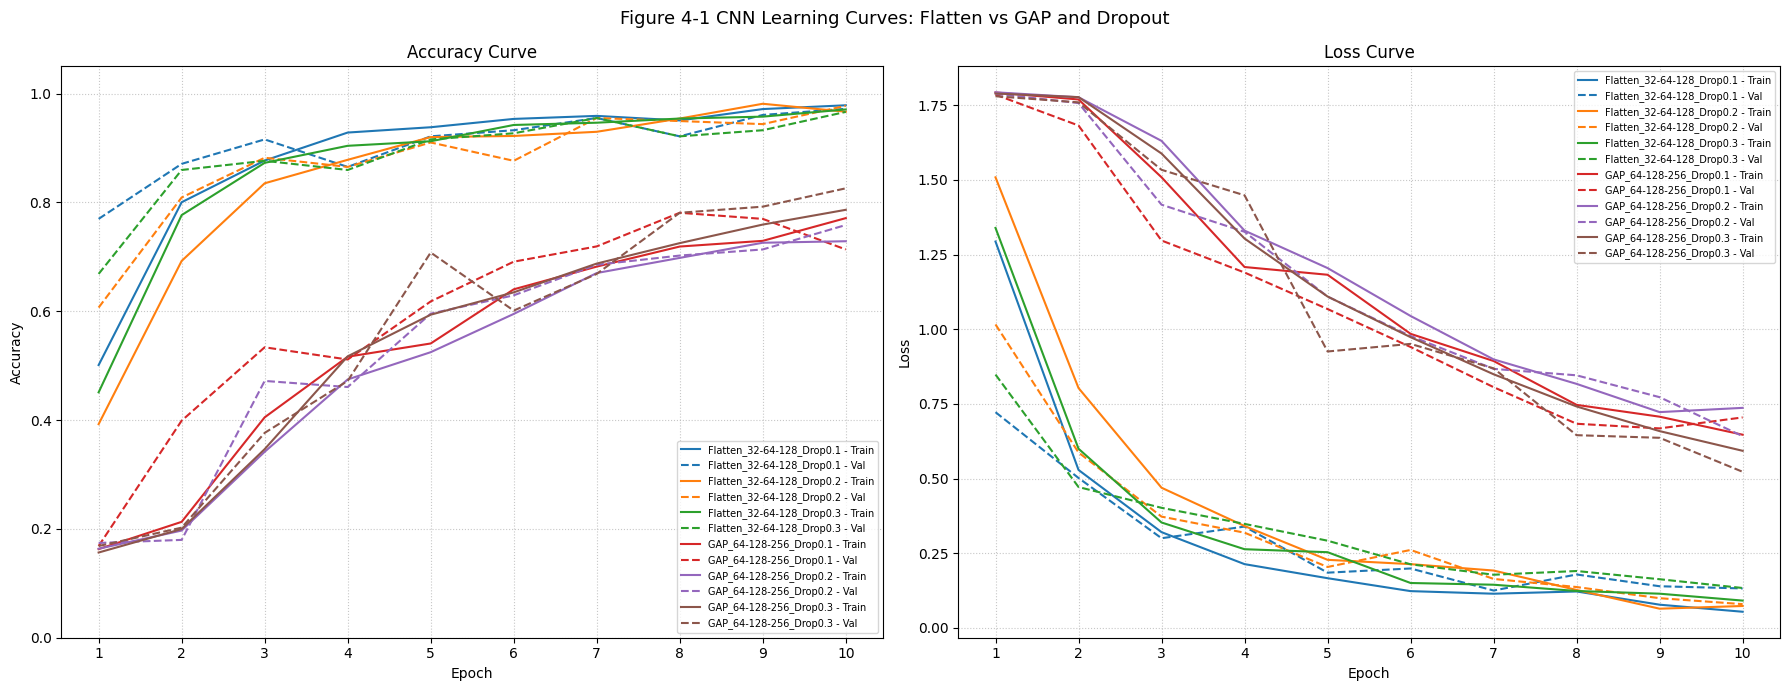

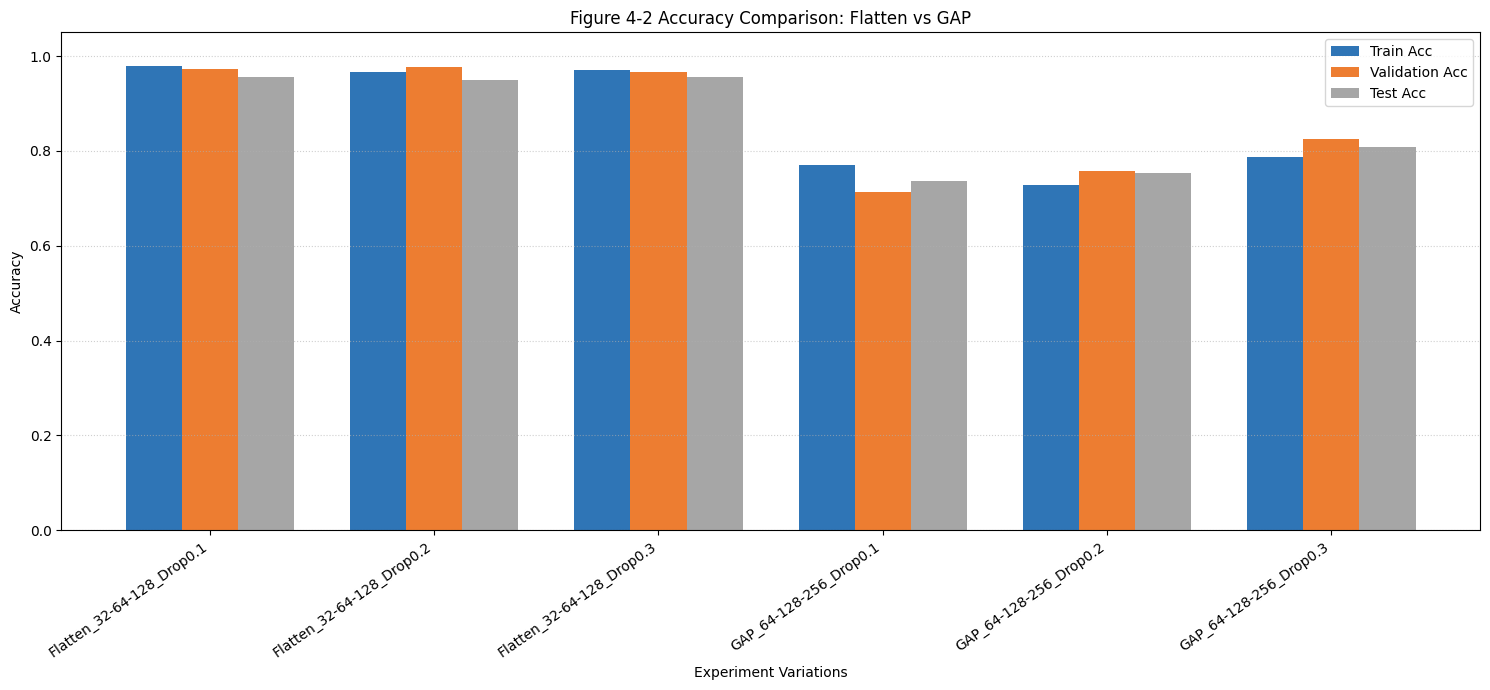

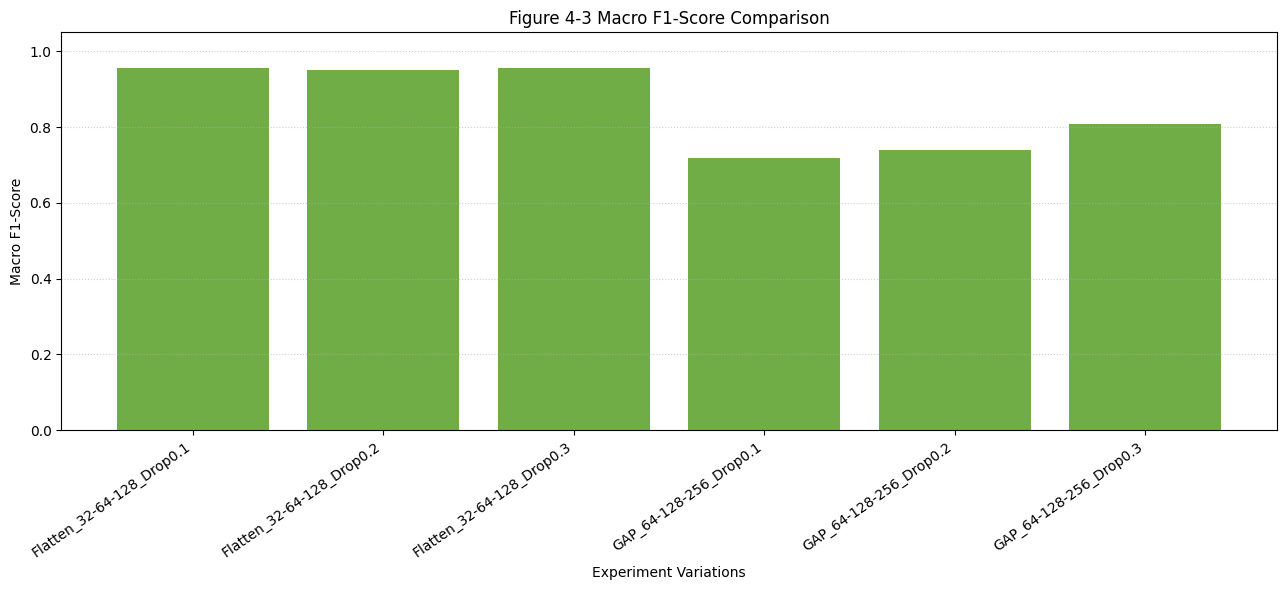


CLASSIFICATION REPORTS ON TEST SET

Classification Report: Flatten_32-64-128_Drop0.1
              precision    recall  f1-score   support

          R1       0.86      1.00      0.92        30
          R2       0.97      0.94      0.95        31
          R3       1.00      1.00      1.00        30
          R4       1.00      0.83      0.91        30
          R5       1.00      1.00      1.00        30
          R6       0.94      0.97      0.95        31

    accuracy                           0.96       182
   macro avg       0.96      0.96      0.96       182
weighted avg       0.96      0.96      0.96       182



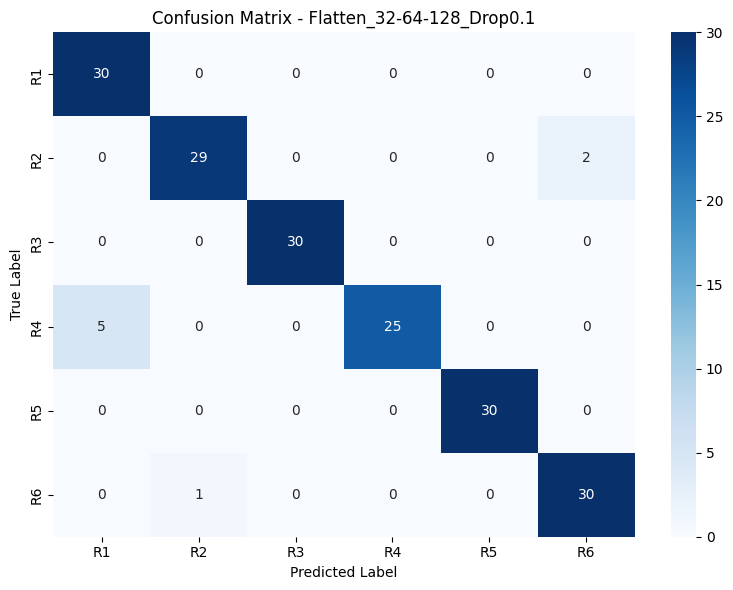


Classification Report: Flatten_32-64-128_Drop0.2
              precision    recall  f1-score   support

          R1       0.85      0.97      0.91        30
          R2       0.97      0.97      0.97        31
          R3       0.94      1.00      0.97        30
          R4       0.96      0.90      0.93        30
          R5       1.00      0.90      0.95        30
          R6       1.00      0.97      0.98        31

    accuracy                           0.95       182
   macro avg       0.95      0.95      0.95       182
weighted avg       0.95      0.95      0.95       182



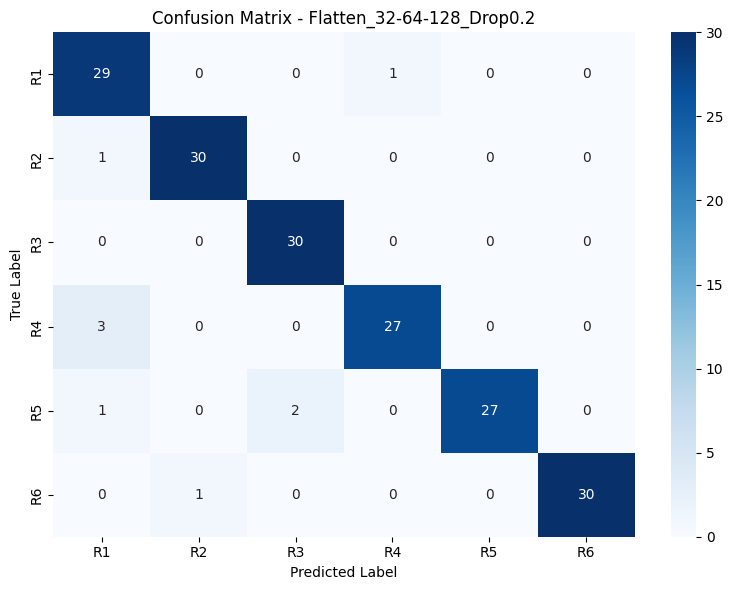


Classification Report: Flatten_32-64-128_Drop0.3
              precision    recall  f1-score   support

          R1       0.83      1.00      0.91        30
          R2       0.97      0.97      0.97        31
          R3       1.00      0.97      0.98        30
          R4       1.00      0.87      0.93        30
          R5       0.97      1.00      0.98        30
          R6       1.00      0.94      0.97        31

    accuracy                           0.96       182
   macro avg       0.96      0.96      0.96       182
weighted avg       0.96      0.96      0.96       182



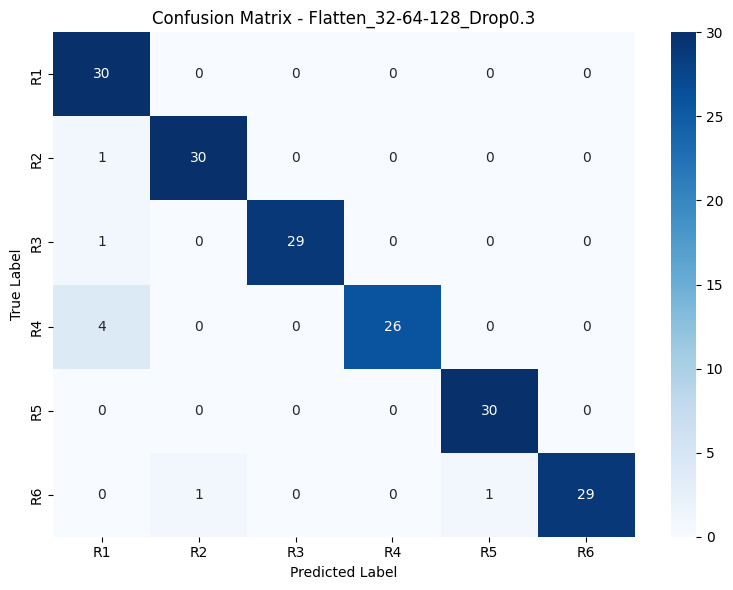


Classification Report: GAP_64-128-256_Drop0.1
              precision    recall  f1-score   support

          R1       1.00      0.23      0.38        30
          R2       0.75      0.77      0.76        31
          R3       0.83      0.80      0.81        30
          R4       0.50      0.87      0.63        30
          R5       0.79      0.90      0.84        30
          R6       0.93      0.84      0.88        31

    accuracy                           0.74       182
   macro avg       0.80      0.74      0.72       182
weighted avg       0.80      0.74      0.72       182



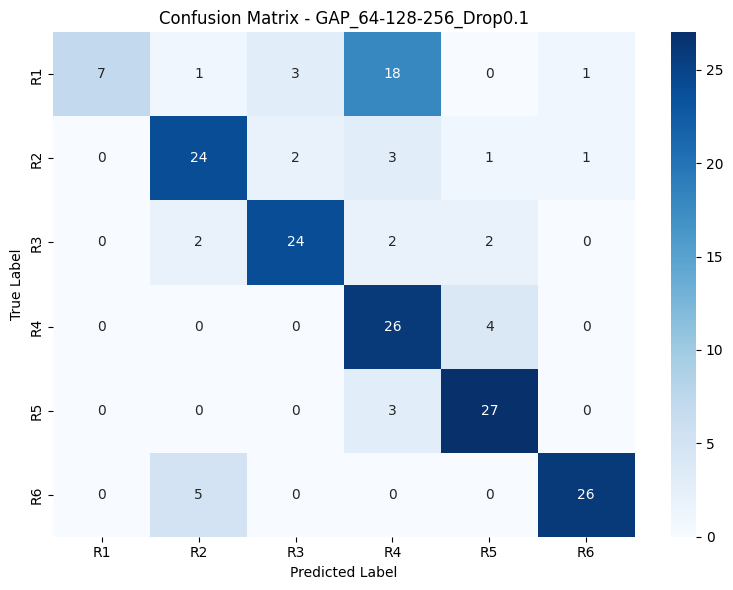


Classification Report: GAP_64-128-256_Drop0.2
              precision    recall  f1-score   support

          R1       0.57      0.80      0.67        30
          R2       0.77      0.74      0.75        31
          R3       0.79      0.90      0.84        30
          R4       0.91      0.33      0.49        30
          R5       0.76      0.87      0.81        30
          R6       0.87      0.87      0.87        31

    accuracy                           0.75       182
   macro avg       0.78      0.75      0.74       182
weighted avg       0.78      0.75      0.74       182



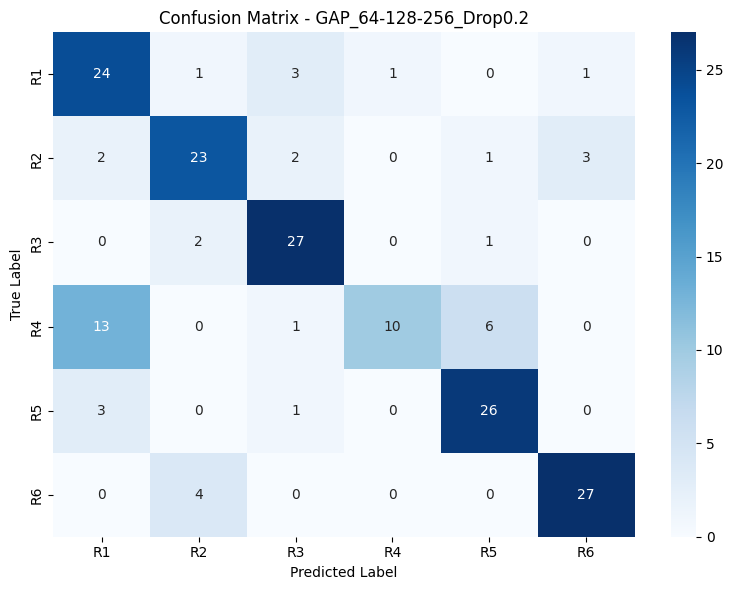


Classification Report: GAP_64-128-256_Drop0.3
              precision    recall  f1-score   support

          R1       0.81      0.70      0.75        30
          R2       0.68      0.84      0.75        31
          R3       0.84      0.87      0.85        30
          R4       0.73      0.80      0.76        30
          R5       0.90      0.87      0.88        30
          R6       0.96      0.77      0.86        31

    accuracy                           0.81       182
   macro avg       0.82      0.81      0.81       182
weighted avg       0.82      0.81      0.81       182



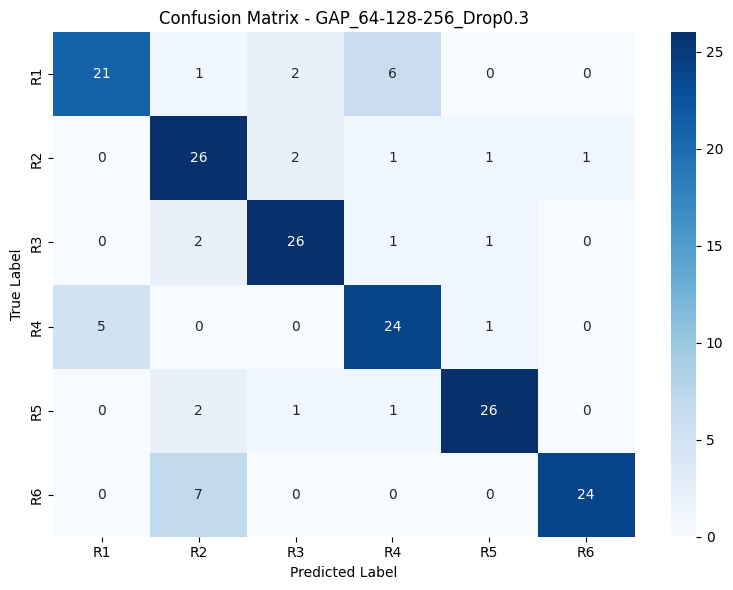


FINAL MODEL COMPARISON


,Model Name,Structure,Dropout Rate,Total Params,Trainable Params,Train Acc,Train Loss,Val Acc,Val Loss,Test Acc,Test Loss,Precision (Macro),Recall (Macro),F1 Score (Macro)
0,Flatten_32-64-128_Drop0.3,Flatten (32-64-128),0.3,8483654,8483654,0.9708,0.0915,0.9663,0.1337,0.9560,0.9804,0.9615,0.9561,0.9565
1,Flatten_32-64-128_Drop0.1,Flatten (32-64-128),0.1,8483654,8483654,0.9784,0.0542,0.9719,0.1323,0.9560,0.8747,0.9602,0.9561,0.9559
2,Flatten_32-64-128_Drop0.2,Flatten (32-64-128),0.2,8483654,8483654,0.9666,0.0735,0.9775,0.0796,0.9505,1.0445,0.9537,0.9504,0.9506
3,GAP_64-128-256_Drop0.3,GAP (64-128-256),0.3,438150,438150,0.7864,0.5931,0.8258,0.5228,0.8077,0.9751,0.8191,0.8077,0.8094
4,GAP_64-128-256_Drop0.2,GAP (64-128-256),0.2,438150,438150,0.7286,0.7369,0.7584,0.6421,0.7527,0.9127,0.7795,0.7522,0.7393
5,GAP_64-128-256_Drop0.1,GAP (64-128-256),0.1,438150,438150,0.7711,0.6470,0.7135,0.7050,0.7363,1.1838,0.8000,0.7355,0.7188



Output files:
Excel results: /content/dropout_experiment_results.xlsx
Saved models: /content/saved_models


In [ ]:

# ============================================================
# CNN EXPERIMENT
# Flatten: 32 -> 64 -> 128
# GAP:     64 -> 128 -> 256
# Dropout: 0.1, 0.2, 0.3
# Total: 6 Models
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. Dataset Configuration & Preparation
# ------------------------------------------------------------

IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = 6

DATASET_DIR = '/content/dataset_split'

train_dir = os.path.join(DATASET_DIR, 'train')
val_dir = os.path.join(DATASET_DIR, 'val')
test_dir = os.path.join(DATASET_DIR, 'test')

# ตรวจสอบ Dataset Paths
for directory in [train_dir, val_dir, test_dir]:
    if not os.path.isdir(directory):
        raise FileNotFoundError(f"Dataset directory not found: {directory}")

# Load datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names

print("Class Names:", class_names)
print("Number of Classes:", len(class_names))

if len(class_names) != NUM_CLASSES:
    raise ValueError(
        f"Expected {NUM_CLASSES} classes, but found {len(class_names)}."
    )

# ตรวจสอบว่า Class ในทุกชุดข้อมูลเรียงตรงกัน
if val_ds.class_names != class_names:
    raise ValueError("Validation class names do not match training classes.")

if test_ds.class_names != class_names:
    raise ValueError("Test class names do not match training classes.")

# Optimize Dataset Pipeline
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Ground truth labels for Test Set
y_test_true = np.concatenate(
    [labels.numpy() for images, labels in test_ds],
    axis=0
)

print("\nDataset preparation completed.")
print("Test samples:", len(y_test_true))


# ------------------------------------------------------------
# 2. Model Builder Function
# Flatten: Filters 32 -> 64 -> 128
# GAP:     Filters 64 -> 128 -> 256
# ------------------------------------------------------------

def build_experiment_model(
    pooling_type='flatten',
    dense_units=256,
    dropout_rate=0.3
):
    pooling_type = pooling_type.lower()

    # เลือกจำนวน Filters ตามรูปแบบการทดลอง
    if pooling_type == 'flatten':
        filters = [32, 64, 128]

    elif pooling_type == 'gap':
        filters = [64, 128, 256]

    else:
        raise ValueError(
            "pooling_type must be either 'flatten' or 'gap'."
        )

    model = models.Sequential(name=f'CNN_{pooling_type}')

    # Input Normalization
    model.add(
        layers.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    )
    model.add(
        layers.Rescaling(1.0 / 255)
    )

    # Convolution Blocks
    for filter_num in filters:
        model.add(
            layers.Conv2D(
                filters=filter_num,
                kernel_size=(3, 3),
                activation='relu',
                padding='same'
            )
        )

        model.add(
            layers.MaxPooling2D(pool_size=(2, 2))
        )

    # Dimensionality Reduction
    if pooling_type == 'flatten':
        model.add(layers.Flatten())

    elif pooling_type == 'gap':
        model.add(layers.GlobalAveragePooling2D())

    # Dense Classifier
    model.add(
        layers.Dense(
            dense_units,
            activation='relu'
        )
    )

    # Dropout
    if dropout_rate > 0:
        model.add(
            layers.Dropout(dropout_rate)
        )

    # Output Layer
    model.add(
        layers.Dense(
            NUM_CLASSES,
            activation='softmax'
        )
    )

    # Compile Model
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model


# ------------------------------------------------------------
# 3. Experiment Configurations (6 Models)
# ------------------------------------------------------------

experiment_configs = [
    # Flatten: 32 -> 64 -> 128
    {
        'name': 'Flatten_32-64-128_Drop0.1',
        'type': 'flatten',
        'dropout': 0.1
    },
    {
        'name': 'Flatten_32-64-128_Drop0.2',
        'type': 'flatten',
        'dropout': 0.2
    },
    {
        'name': 'Flatten_32-64-128_Drop0.3',
        'type': 'flatten',
        'dropout': 0.3
    },

    # GAP: 64 -> 128 -> 256
    {
        'name': 'GAP_64-128-256_Drop0.1',
        'type': 'gap',
        'dropout': 0.1
    },
    {
        'name': 'GAP_64-128-256_Drop0.2',
        'type': 'gap',
        'dropout': 0.2
    },
    {
        'name': 'GAP_64-128-256_Drop0.3',
        'type': 'gap',
        'dropout': 0.3
    }
]

histories = {}
results_summary = []

SAVE_DIR = '/content/saved_models'
os.makedirs(SAVE_DIR, exist_ok=True)


# ------------------------------------------------------------
# 4. Run Experiments & Save Models
# ------------------------------------------------------------

for exp_index, cfg in enumerate(experiment_configs, start=1):

    exp_name = cfg['name']
    pool_type = cfg['type']
    drop_rate = cfg['dropout']

    print("\n" + "=" * 70)
    print(f"Experiment {exp_index}/{len(experiment_configs)}")
    print(f"Model: {exp_name}")
    print(f"Pooling: {pool_type.upper()}")
    print(f"Dropout: {drop_rate}")
    print("=" * 70)

    # สร้าง Model
    tf.keras.backend.clear_session()

    model = build_experiment_model(
        pooling_type=pool_type,
        dense_units=256,
        dropout_rate=drop_rate
    )

    # คำนวณ Parameters
    total_params = model.count_params()

    trainable_params = int(
        np.sum([
            tf.keras.backend.count_params(w)
            for w in model.trainable_weights
        ])
    )

    print(f"Total Parameters: {total_params:,}")
    print(f"Trainable Parameters: {trainable_params:,}")

    # แสดง Model Architecture
    model.summary()

    # Train Model
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )

    histories[exp_name] = history.history

    # เก็บค่าผลลัพธ์จาก Epoch สุดท้าย
    train_acc = history.history['accuracy'][-1]
    train_loss = history.history['loss'][-1]

    val_acc = history.history['val_accuracy'][-1]
    val_loss = history.history['val_loss'][-1]

    # Evaluate on Test Set
    test_loss, test_acc = model.evaluate(
        test_ds,
        verbose=0
    )

    # Predict Test Set
    y_pred_probs = model.predict(
        test_ds,
        verbose=0
    )

    y_pred = np.argmax(y_pred_probs, axis=1)

    # Calculate Classification Metrics
    p_macro = precision_score(
        y_test_true,
        y_pred,
        average='macro',
        zero_division=0
    )

    r_macro = recall_score(
        y_test_true,
        y_pred,
        average='macro',
        zero_division=0
    )

    f1_macro = f1_score(
        y_test_true,
        y_pred,
        average='macro',
        zero_division=0
    )

    # Save Results
    results_summary.append({
        'Model Name': exp_name,
        'Structure': (
            'Flatten (32-64-128)'
            if pool_type == 'flatten'
            else 'GAP (64-128-256)'
        ),
        'Dropout Rate': drop_rate,
        'Total Params': total_params,
        'Trainable Params': trainable_params,
        'Train Acc': round(train_acc, 4),
        'Train Loss': round(train_loss, 4),
        'Val Acc': round(val_acc, 4),
        'Val Loss': round(val_loss, 4),
        'Test Acc': round(test_acc, 4),
        'Test Loss': round(test_loss, 4),
        'Precision (Macro)': round(p_macro, 4),
        'Recall (Macro)': round(r_macro, 4),
        'F1 Score (Macro)': round(f1_macro, 4)
    })

    # Save Keras Model
    keras_path = os.path.join(
        SAVE_DIR,
        f'model_{exp_name}.keras'
    )

    model.save(keras_path)

    # Convert and Save TFLite Model
    tflite_path = os.path.join(
        SAVE_DIR,
        f'model_{exp_name}.tflite'
    )

    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(model)
        tflite_model_bytes = converter.convert()

        with open(tflite_path, 'wb') as f:
            f.write(tflite_model_bytes)

        print(f"Saved Keras: {keras_path}")
        print(f"Saved TFLite: {tflite_path}")

    except Exception as e:
        print(f"TFLite conversion failed for {exp_name}: {e}")
        print("The Keras model was saved successfully.")

    # แสดงผลของแต่ละโมเดล
    print("\nTest Results")
    print(f"Test Accuracy : {test_acc:.4f}")
    print(f"Test Loss     : {test_loss:.4f}")
    print(f"Precision     : {p_macro:.4f}")
    print(f"Recall        : {r_macro:.4f}")
    print(f"F1 Score      : {f1_macro:.4f}")


# ------------------------------------------------------------
# 5. Export Summary to Excel
# ------------------------------------------------------------

df_results = pd.DataFrame(results_summary)

print("\n" + "=" * 90)
print("EXPERIMENT RESULTS SUMMARY")
print("=" * 90)

display(df_results)

excel_filename = '/content/dropout_experiment_results.xlsx'

df_results.to_excel(
    excel_filename,
    index=False
)

print(f"\nSaved summary table to: {excel_filename}")


# ------------------------------------------------------------
# 6. Plot Visualizations
# ------------------------------------------------------------

# ------------------------------------------------------------
# 6.1 Learning Curves (Accuracy & Loss)
# ------------------------------------------------------------

fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(18, 7)
)

colors = plt.cm.tab10.colors[:len(histories)]

for (name, hist), color in zip(histories.items(), colors):

    # Accuracy
    ax1.plot(
        range(1, len(hist['accuracy']) + 1),
        hist['accuracy'],
        label=f'{name} - Train',
        color=color,
        linestyle='-'
    )

    ax1.plot(
        range(1, len(hist['val_accuracy']) + 1),
        hist['val_accuracy'],
        label=f'{name} - Val',
        color=color,
        linestyle='--'
    )

    # Loss
    ax2.plot(
        range(1, len(hist['loss']) + 1),
        hist['loss'],
        label=f'{name} - Train',
        color=color,
        linestyle='-'
    )

    ax2.plot(
        range(1, len(hist['val_loss']) + 1),
        hist['val_loss'],
        label=f'{name} - Val',
        color=color,
        linestyle='--'
    )

ax1.set_title('Accuracy Curve')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.set_xticks(range(1, EPOCHS + 1))
ax1.set_ylim(0, 1.05)
ax1.legend(loc='lower right', fontsize=7)
ax1.grid(True, linestyle=':', alpha=0.7)

ax2.set_title('Loss Curve')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.set_xticks(range(1, EPOCHS + 1))
ax2.legend(loc='upper right', fontsize=7)
ax2.grid(True, linestyle=':', alpha=0.7)

plt.suptitle(
    'Figure 4-1 CNN Learning Curves: Flatten vs GAP and Dropout',
    fontsize=13
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6.2 Accuracy Comparison Bar Chart
# ------------------------------------------------------------

x = np.arange(len(df_results))
width = 0.25

plt.figure(figsize=(15, 7))

plt.bar(
    x - width,
    df_results['Train Acc'],
    width,
    label='Train Acc',
    color='#2F75B6'
)

plt.bar(
    x,
    df_results['Val Acc'],
    width,
    label='Validation Acc',
    color='#ED7D31'
)

plt.bar(
    x + width,
    df_results['Test Acc'],
    width,
    label='Test Acc',
    color='#A6A6A6'
)

plt.xlabel('Experiment Variations')
plt.ylabel('Accuracy')
plt.title('Figure 4-2 Accuracy Comparison: Flatten vs GAP')

plt.xticks(
    x,
    df_results['Model Name'],
    rotation=35,
    ha='right'
)

plt.ylim(0, 1.05)
plt.legend()
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6.3 Test F1-Score Comparison
# ------------------------------------------------------------

plt.figure(figsize=(13, 6))

plt.bar(
    df_results['Model Name'],
    df_results['F1 Score (Macro)'],
    color='#70AD47'
)

plt.xlabel('Experiment Variations')
plt.ylabel('Macro F1-Score')
plt.title('Figure 4-3 Macro F1-Score Comparison')

plt.xticks(rotation=35, ha='right')
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Save Final Confusion Matrix & Classification Report
#    for Each Model
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("CLASSIFICATION REPORTS ON TEST SET")
print("=" * 90)

for cfg in experiment_configs:

    exp_name = cfg['name']
    keras_path = os.path.join(
        SAVE_DIR,
        f'model_{exp_name}.keras'
    )

    if not os.path.exists(keras_path):
        continue

    print(f"\n{'=' * 70}")
    print(f"Classification Report: {exp_name}")
    print("=" * 70)

    # Load saved model to evaluate consistently
    trained_model = tf.keras.models.load_model(keras_path)

    y_pred_probs = trained_model.predict(
        test_ds,
        verbose=0
    )

    y_pred = np.argmax(y_pred_probs, axis=1)

    print(
        classification_report(
            y_test_true,
            y_pred,
            labels=np.arange(NUM_CLASSES),
            target_names=class_names,
            zero_division=0
        )
    )

    cm = confusion_matrix(
        y_test_true,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.title(f'Confusion Matrix - {exp_name}')
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 8. Final Summary
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("FINAL MODEL COMPARISON")
print("=" * 90)

display(
    df_results.sort_values(
        by='F1 Score (Macro)',
        ascending=False
    ).reset_index(drop=True)
)

print("\nOutput files:")
print(f"Excel results: {excel_filename}")
print(f"Saved models: {SAVE_DIR}")

model ที่ดีที่สุด

Found 1437 files belonging to 6 classes.
Found 178 files belonging to 6 classes.
Found 182 files belonging to 6 classes.
Class Names: ['R1', 'R2', 'R3', 'R4', 'R5', 'R6']


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_4 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │     8,388,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,483,654 (32.36 MB)

 Trainable params: 8,483,654 (32.36 MB)

 Non-trainable params: 0 (0.00 B)


Starting Model Training (Initial RAM: 2181.59 MB)
Epoch 1/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 8s 101ms/step - accuracy: 0.4725 - loss: 1.3800 - val_accuracy: 0.6910 - val_loss: 0.8463
Epoch 2/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.7383 - loss: 0.6655 - val_accuracy: 0.8034 - val_loss: 0.5704
Epoch 3/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.8629 - loss: 0.3666 - val_accuracy: 0.8596 - val_loss: 0.5329
Epoch 4/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9047 - loss: 0.2474 - val_accuracy: 0.8483 - val_loss: 0.3632
Epoch 5/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9388 - loss: 0.1658 - val_accuracy: 0.9045 - val_loss: 0.2670
Epoch 6/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9381 - loss: 0.1504 - val_accuracy: 0.9382 - val_loss: 0.1812
Epoch 7/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9603 - loss: 0.1008 - val_accuracy: 0.9663 - val_loss: 0.1551
Epoch 8/10
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accura

Saved artifact at '/tmp/tmpc2ssqslx'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor_48')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  138644809363152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138644809365264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138644805235152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138644805235728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138644805235344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138644805235920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138644805234960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138640472674704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138640472674512: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138640472675088: TensorSpec(shape=(), dtype=tf.resource, name=None)
Saved artifac

,Model Name,Total Params,Train Acc,Train Loss,Val Acc,Val Loss,Test Acc,Test Loss,Precision (Macro),Recall (Macro),...,Precision (Weighted),Recall (Weighted),F1 Score (Weighted),Training Time (sec),RAM Usage Increase (MB),Inference Time (ms/img),Keras Size (MB),FP32 Size (MB),FP16 Size (MB),INT8 Size (MB)
0,Flatten_32-64-128_Drop0.1,"8,483,654",0.9833,0.0499,0.9663,0.1032,0.9615,0.8735,0.9643,0.9615,...,0.9643,0.9615,0.9614,18.28,66.6,13.96,97.14,32.37,16.19,8.11



Saved summary Excel table to: /content/optimal_model_evaluation_results.xlsx


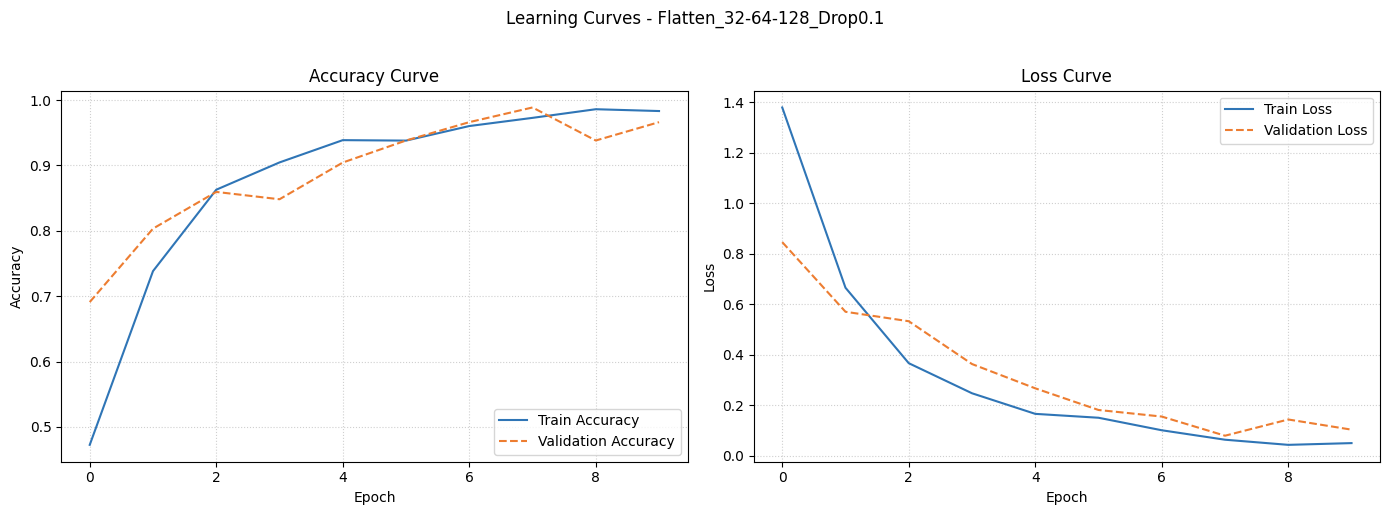

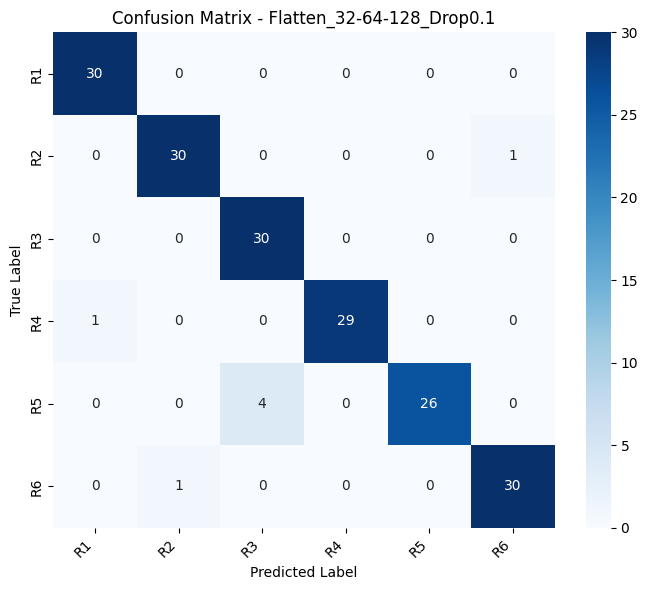

In [ ]:
import os
import time
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# ----------------------------------------------------
# 1. Dataset Configuration & Preparation
# ----------------------------------------------------
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = 6
DATASET_DIR = '/content/dataset_split'

train_dir = os.path.join(DATASET_DIR, 'train')
val_dir = os.path.join(DATASET_DIR, 'val')
test_dir = os.path.join(DATASET_DIR, 'test')

# Load datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=True
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)

class_names = train_ds.class_names
print("Class Names:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

# Ground truth labels for Test Set
y_test_true = np.concatenate([y for x, y in test_ds], axis=0)

# ----------------------------------------------------
# 2. Build Optimal Model Architecture
# ----------------------------------------------------
def build_optimal_model():
    model = models.Sequential([
        layers.Rescaling(1./255, input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),

        # Conv Block 1
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Conv Block 3
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.MaxPooling2D((2, 2)),

        # Dense Classifier with Flatten & Dropout 0.1
        layers.Flatten(),
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.1),
        layers.Dense(NUM_CLASSES, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model = build_optimal_model()
model.summary()

# ----------------------------------------------------
# 3. Train Model & Measure Training Resources
# ----------------------------------------------------
process = psutil.Process(os.getpid())
mem_before = process.memory_info().rss / (1024 ** 2)

print("\n" + "="*50)
print(f"Starting Model Training (Initial RAM: {mem_before:.2f} MB)")
print("="*50)
start_train_time = time.time()

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=1
)

end_train_time = time.time()
mem_after = process.memory_info().rss / (1024 ** 2)

total_train_time = end_train_time - start_train_time
ram_increase = mem_after - mem_before

# ----------------------------------------------------
# 4. Standard Metrics Evaluation
# ----------------------------------------------------
train_acc = history.history['accuracy'][-1]
train_loss = history.history['loss'][-1]
val_acc = history.history['val_accuracy'][-1]
val_loss = history.history['val_loss'][-1]

# Test Set Evaluation
test_loss, test_acc = model.evaluate(test_ds, verbose=0)

# Model Predictions
y_pred_probs = model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

# Calculate sklearn metrics
p_macro = precision_score(y_test_true, y_pred, average='macro', zero_division=0)
r_macro = recall_score(y_test_true, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test_true, y_pred, average='macro', zero_division=0)

p_weighted = precision_score(y_test_true, y_pred, average='weighted', zero_division=0)
r_weighted = recall_score(y_test_true, y_pred, average='weighted', zero_division=0)
f1_weighted = f1_score(y_test_true, y_pred, average='weighted', zero_division=0)

print("\n" + "="*60)
print("CLASSIFICATION REPORT (Test Set)")
print("="*60)
print(classification_report(y_test_true, y_pred, target_names=class_names, digits=4, zero_division=0))

# ----------------------------------------------------
# 5. Measure Inference Time
# ----------------------------------------------------
sample_images, _ = next(iter(test_ds))
start_inf_time = time.time()
_ = model.predict(sample_images, verbose=0)
end_inf_time = time.time()
inference_time_per_img = ((end_inf_time - start_inf_time) / len(sample_images)) * 1000

# ----------------------------------------------------
# 6. Quantization & File Size Measurements
# ----------------------------------------------------
os.makedirs('/content/final_models', exist_ok=True)
keras_path = '/content/final_models/optimal_cnn.keras'
model.save(keras_path)

# FP32 TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_fp32 = converter.convert()
fp32_path = '/content/final_models/model_fp32.tflite'
with open(fp32_path, 'wb') as f: f.write(tflite_fp32)

# FP16 TFLite
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]
tflite_fp16 = converter.convert()
fp16_path = '/content/final_models/model_fp16.tflite'
with open(fp16_path, 'wb') as f: f.write(tflite_fp16)

# INT8 Dynamic Quantization TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_int8 = converter.convert()
int8_path = '/content/final_models/model_int8.tflite'
with open(int8_path, 'wb') as f: f.write(tflite_int8)

size_keras = os.path.getsize(keras_path) / (1024 * 1024)
size_fp32 = os.path.getsize(fp32_path) / (1024 * 1024)
size_fp16 = os.path.getsize(fp16_path) / (1024 * 1024)
size_int8 = os.path.getsize(int8_path) / (1024 * 1024)

# ----------------------------------------------------
# 7. Summary DataFrame & Export to Excel
# ----------------------------------------------------
summary_data = [{
    'Model Name': 'Flatten_32-64-128_Drop0.1',
    'Total Params': f"{model.count_params():,}",
    'Train Acc': round(train_acc, 4),
    'Train Loss': round(train_loss, 4),
    'Val Acc': round(val_acc, 4),
    'Val Loss': round(val_loss, 4),
    'Test Acc': round(test_acc, 4),
    'Test Loss': round(test_loss, 4),
    'Precision (Macro)': round(p_macro, 4),
    'Recall (Macro)': round(r_macro, 4),
    'F1 Score (Macro)': round(f1_macro, 4),
    'Precision (Weighted)': round(p_weighted, 4),
    'Recall (Weighted)': round(r_weighted, 4),
    'F1 Score (Weighted)': round(f1_weighted, 4),
    'Training Time (sec)': round(total_train_time, 2),
    'RAM Usage Increase (MB)': round(ram_increase, 2),
    'Inference Time (ms/img)': round(inference_time_per_img, 2),
    'Keras Size (MB)': round(size_keras, 2),
    'FP32 Size (MB)': round(size_fp32, 2),
    'FP16 Size (MB)': round(size_fp16, 2),
    'INT8 Size (MB)': round(size_int8, 2)
}]

df_summary = pd.DataFrame(summary_data)
print("\n" + "="*80)
print("FINAL EVALUATION SUMMARY TABLE")
print("="*80)
display(df_summary)

excel_filename = '/content/optimal_model_evaluation_results.xlsx'
df_summary.to_excel(excel_filename, index=False)
print(f"\nSaved summary Excel table to: {excel_filename}")

# ----------------------------------------------------
# 8. Visualizations (Learning Curves & Confusion Matrix)
# ----------------------------------------------------
# 8.1 Learning Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(history.history['accuracy'], label='Train Accuracy', color='#2F75B6')
ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='#ED7D31', linestyle='--')
ax1.set_title('Accuracy Curve')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend(loc='lower right')
ax1.grid(True, linestyle=':', alpha=0.6)

ax2.plot(history.history['loss'], label='Train Loss', color='#2F75B6')
ax2.plot(history.history['val_loss'], label='Validation Loss', color='#ED7D31', linestyle='--')
ax2.set_title('Loss Curve')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Learning Curves - Flatten_32-64-128_Drop0.1', y=1.02)
plt.tight_layout()
plt.show()

# 8.2 Confusion Matrix
cm = confusion_matrix(y_test_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Flatten_32-64-128_Drop0.1')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

ทดลอง transfer model

In [ ]:
import os
import time
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16, MobileNetV2, EfficientNetB0
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_v2_preprocess
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# ----------------------------------------------------
# 1. Dataset Configuration & Preparation
# ----------------------------------------------------
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = 6
DATASET_DIR = '/content/dataset_split'

train_dir = os.path.join(DATASET_DIR, 'train')
val_dir = os.path.join(DATASET_DIR, 'val')
test_dir = os.path.join(DATASET_DIR, 'test')

# Load datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=True
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)

class_names = train_ds.class_names
print("Class Names:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

y_test_true = np.concatenate([y for x, y in test_ds], axis=0)
sample_images, _ = next(iter(test_ds))

# ----------------------------------------------------
# 2. Define Function to Build, Train, and Evaluate Models
# ----------------------------------------------------
def run_experiment(model_name):
    print("\n" + "="*80)
    print(f"🚀 STARTING EXPERIMENT FOR: {model_name}")
    print("="*80)

    # ก. โหลด Convolutional Base ของแต่ละสถาปัตยกรรม
    input_shape = (IMG_HEIGHT, IMG_WIDTH, 3)
    inputs = tf.keras.Input(shape=input_shape)

    if model_name == 'VGG16':
        x = layers.Lambda(vgg16_preprocess)(inputs)
        base_model = VGG16(input_shape=input_shape, include_top=False, weights='imagenet')(x)
    elif model_name == 'MobileNetV2':
        x = layers.Lambda(mobilenet_v2_preprocess)(inputs)
        base_model = MobileNetV2(input_shape=input_shape, include_top=False, weights='imagenet')(x)
    elif model_name == 'EfficientNetB0':
        # EfficientNet มี preprocessing ในตัวอยู่แล้วใน Keras
        base_model = EfficientNetB0(input_shape=input_shape, include_top=False, weights='imagenet')(inputs)

    # กำหนดให้ Base Model ไม่ถูก Train (ปรับแต่งตามความเหมาะสมของงานวิจัย)
    # base_model.trainable = False

    # ข. เชื่อมต่อชั้นจำแนกประเภท (Top Layers) ที่ปรับแต่งสำหรับงานวิจัยนี้
    x = layers.Flatten()(base_model) # หรือเปลี่ยนเป็น GlobalAveragePooling2D() หากพารามิเตอร์เยอะเกินไป
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.1)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = models.Model(inputs, outputs, name=model_name)

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # ค. บันทึกทรัพยากรระบบก่อน Train
    process = psutil.Process(os.getpid())
    mem_before = process.memory_info().rss / (1024 ** 2)
    start_train_time = time.time()

    # ง. Train Model
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )

    # จ. บันทึกทรัพยากรระบบหลัง Train
    end_train_time = time.time()
    mem_after = process.memory_info().rss / (1024 ** 2)
    total_train_time = end_train_time - start_train_time
    ram_increase = max(0, mem_after - mem_before)

    # ฉ. ดึงค่า Metrics ต่างๆ
    train_acc = history.history['accuracy'][-1]
    train_loss = history.history['loss'][-1]
    val_acc = history.history['val_accuracy'][-1]
    val_loss = history.history['val_loss'][-1]
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    y_pred_probs = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    p_weighted = precision_score(y_test_true, y_pred, average='weighted', zero_division=0)
    r_weighted = recall_score(y_test_true, y_pred, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_test_true, y_pred, average='weighted', zero_division=0)

    # ช. วัดความเร็วในการประมวลผล (Inference Time)
    start_inf_time = time.time()
    _ = model.predict(sample_images, verbose=0)
    end_inf_time = time.time()
    inference_time_per_img = ((end_inf_time - start_inf_time) / len(sample_images)) * 1000

    # ----------------------------------------------------
    # 3. วาดกราฟ Learning Curves และ Confusion Matrix
    # ----------------------------------------------------
    # Learning Curves
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history.history['accuracy'], label='Train Accuracy', color='#2F75B6')
    ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='#ED7D31', linestyle='--')
    ax1.set_title(f'Accuracy Curve - {model_name}')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend(loc='lower right')
    ax1.grid(True, linestyle=':', alpha=0.6)

    ax2.plot(history.history['loss'], label='Train Loss', color='#2F75B6')
    ax2.plot(history.history['val_loss'], label='Validation Loss', color='#ED7D31', linestyle='--')
    ax2.set_title(f'Loss Curve - {model_name}')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend(loc='upper right')
    ax2.grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

    # Confusion Matrix
    cm = confusion_matrix(y_test_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    print("\n" + "-"*60)
    print(f"CLASSIFICATION REPORT : {model_name}")
    print("-"*60)
    print(classification_report(y_test_true, y_pred, target_names=class_names, digits=4, zero_division=0))

    return {
        'Model Name': model_name,
        'Total Params': f"{model.count_params():,}",
        'Train Acc (%)': round(train_acc * 100, 2),
        'Validation Acc (%)': round(val_acc * 100, 2),
        'Test Acc (%)': round(test_acc * 100, 2),
        'Train Loss': round(train_loss, 4),
        'Validation Loss': round(val_loss, 4),
        'Precision (Weighted)': round(p_weighted, 4),
        'Recall (Weighted)': round(r_weighted, 4),
        'F1 Score (Weighted)': round(f1_weighted, 4),
        'Training Time (sec)': round(total_train_time, 2),
        'RAM Usage (MB)': round(ram_increase, 2),
        'Inference Time (ms/img)': round(inference_time_per_img, 2)
    }

# ----------------------------------------------------
# 4. Execute the Experiments & Export
# ----------------------------------------------------
architectures = ['VGG16', 'MobileNetV2', 'EfficientNetB0']
summary_results = []

for arch in architectures:
    # เคลียร์ Memory เซสชั่นเก่าเพื่อป้องกัน RAM ค้างระหว่างการเทรน
    tf.keras.backend.clear_session()
    result = run_experiment(arch)
    summary_results.append(result)

# สร้าง DataFrame สรุปและ Export เป็น Excel
df_summary = pd.DataFrame(summary_results)
print("\n" + "="*80)
print("FINAL EVALUATION SUMMARY TABLE")
print("="*80)
display(df_summary)

excel_filename = '/content/comparative_model_evaluation_results.xlsx'
df_summary.to_excel(excel_filename, index=False)
print(f"\n✅ Saved comparative summary Excel table to: {excel_filename}")

บันทึก model pretrain

In [ ]:
import os
import time
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16, MobileNetV2, EfficientNetB0
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_v2_preprocess
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report

# ----------------------------------------------------
# 1. Dataset Configuration & Preparation
# ----------------------------------------------------
IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = 6
DATASET_DIR = '/content/dataset_split'
SAVE_MODEL_DIR = '/content/final_models'

os.makedirs(SAVE_MODEL_DIR, exist_ok=True)

train_dir = os.path.join(DATASET_DIR, 'train')
val_dir = os.path.join(DATASET_DIR, 'val')
test_dir = os.path.join(DATASET_DIR, 'test')

# Load datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=True
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)

class_names = train_ds.class_names
print("Class Names:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

y_test_true = np.concatenate([y for x, y in test_ds], axis=0)
sample_images, _ = next(iter(test_ds))

# ----------------------------------------------------
# 2. Define Function to Build, Train, Quantize, and Evaluate Models
# ----------------------------------------------------
def run_experiment(model_name):
    print("\n" + "="*80)
    print(f"🚀 STARTING EXPERIMENT FOR: {model_name}")
    print("="*80)

    # ก. โหลด Convolutional Base
    input_shape = (IMG_HEIGHT, IMG_WIDTH, 3)
    inputs = tf.keras.Input(shape=input_shape)

    if model_name == 'VGG16':
        x = layers.Lambda(vgg16_preprocess)(inputs)
        base_model = VGG16(input_shape=input_shape, include_top=False, weights='imagenet')(x)
    elif model_name == 'MobileNetV2':
        x = layers.Lambda(mobilenet_v2_preprocess)(inputs)
        base_model = MobileNetV2(input_shape=input_shape, include_top=False, weights='imagenet')(x)
    elif model_name == 'EfficientNetB0':
        base_model = EfficientNetB0(input_shape=input_shape, include_top=False, weights='imagenet')(inputs)

    # ข. เชื่อมต่อ Top Layers
    x = layers.Flatten()(base_model)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.1)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = models.Model(inputs, outputs, name=model_name)

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # ค. วัดทรัพยากรระบบก่อน Train
    process = psutil.Process(os.getpid())
    mem_before = process.memory_info().rss / (1024 ** 2)
    start_train_time = time.time()

    # ง. Train Model
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )

    end_train_time = time.time()
    mem_after = process.memory_info().rss / (1024 ** 2)
    total_train_time = end_train_time - start_train_time
    ram_increase = max(0, mem_after - mem_before)

    # จ. บันทึก Keras Model และแปลงเป็น TFLite (FP32, FP16, INT8)
    keras_path = os.path.join(SAVE_MODEL_DIR, f"{model_name}.keras")
    model.save(keras_path)

    # 1. Standard FP32 TFLite
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    tflite_fp32 = converter.convert()
    fp32_path = os.path.join(SAVE_MODEL_DIR, f"{model_name}_fp32.tflite")
    with open(fp32_path, 'wb') as f:
        f.write(tflite_fp32)

    # 2. FP16 Quantization TFLite
    converter_fp16 = tf.lite.TFLiteConverter.from_keras_model(model)
    converter_fp16.optimizations = [tf.lite.Optimize.DEFAULT]
    converter_fp16.target_spec.supported_types = [tf.float16]
    tflite_fp16 = converter_fp16.convert()
    fp16_path = os.path.join(SAVE_MODEL_DIR, f"{model_name}_fp16.tflite")
    with open(fp16_path, 'wb') as f:
        f.write(tflite_fp16)

    # 3. Dynamic Range INT8 Quantization TFLite
    converter_int8 = tf.lite.TFLiteConverter.from_keras_model(model)
    converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_int8 = converter_int8.convert()
    int8_path = os.path.join(SAVE_MODEL_DIR, f"{model_name}_int8.tflite")
    with open(int8_path, 'wb') as f:
        f.write(tflite_int8)

    # คำนวณขนาดไฟล์ (MB)
    size_keras = os.path.getsize(keras_path) / (1024 * 1024)
    size_fp32 = os.path.getsize(fp32_path) / (1024 * 1024)
    size_fp16 = os.path.getsize(fp16_path) / (1024 * 1024)
    size_int8 = os.path.getsize(int8_path) / (1024 * 1024)

    # ฉ. ประเมินค่า Metrics
    train_acc = history.history['accuracy'][-1]
    train_loss = history.history['loss'][-1]
    val_acc = history.history['val_accuracy'][-1]
    val_loss = history.history['val_loss'][-1]
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    y_pred_probs = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    p_weighted = precision_score(y_test_true, y_pred, average='weighted', zero_division=0)
    r_weighted = recall_score(y_test_true, y_pred, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_test_true, y_pred, average='weighted', zero_division=0)

    # ช. วัดเวลา Inference Time
    start_inf_time = time.time()
    _ = model.predict(sample_images, verbose=0)
    end_inf_time = time.time()
    inference_time_per_img = ((end_inf_time - start_inf_time) / len(sample_images)) * 1000

    # ----------------------------------------------------
    # Plot Visualizations
    # ----------------------------------------------------
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history.history['accuracy'], label='Train Accuracy', color='#2F75B6')
    ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='#ED7D31', linestyle='--')
    ax1.set_title(f'Accuracy Curve - {model_name}')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend(loc='lower right')
    ax1.grid(True, linestyle=':', alpha=0.6)

    ax2.plot(history.history['loss'], label='Train Loss', color='#2F75B6')
    ax2.plot(history.history['val_loss'], label='Validation Loss', color='#ED7D31', linestyle='--')
    ax2.set_title(f'Loss Curve - {model_name}')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend(loc='upper right')
    ax2.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

    cm = confusion_matrix(y_test_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    print("\n" + "-"*60)
    print(f"CLASSIFICATION REPORT : {model_name}")
    print("-"*60)
    print(classification_report(y_test_true, y_pred, target_names=class_names, digits=4, zero_division=0))

    return {
        'Model Name': model_name,
        'Total Params': f"{model.count_params():,}",
        'Train Acc (%)': round(train_acc * 100, 2),
        'Validation Acc (%)': round(val_acc * 100, 2),
        'Test Acc (%)': round(test_acc * 100, 2),
        'Train Loss': round(train_loss, 4),
        'Validation Loss': round(val_loss, 4),
        'Precision (Weighted)': round(p_weighted, 4),
        'Recall (Weighted)': round(r_weighted, 4),
        'F1 Score (Weighted)': round(f1_weighted, 4),
        'Training Time (sec)': round(total_train_time, 2),
        'RAM Usage (MB)': round(ram_increase, 2),
        'Inference Time (ms/img)': round(inference_time_per_img, 2),
        'Keras Size (MB)': round(size_keras, 2),
        'FP32 Size (MB)': round(size_fp32, 2),
        'FP16 Size (MB)': round(size_fp16, 2),
        'INT8 Size (MB)': round(size_int8, 2)
    }

# ----------------------------------------------------
# 3. Execute Experiments & Export Summary
# ----------------------------------------------------
architectures = ['VGG16', 'MobileNetV2', 'EfficientNetB0']
summary_results = []

for arch in architectures:
    tf.keras.backend.clear_session()
    result = run_experiment(arch)
    summary_results.append(result)

df_summary = pd.DataFrame(summary_results)
print("\n" + "="*80)
print("FINAL EVALUATION SUMMARY TABLE WITH TFLITE SIZES")
print("="*80)
display(df_summary)

excel_filename = '/content/comparative_tflite_evaluation_results.xlsx'
df_summary.to_excel(excel_filename, index=False)
print(f"\nSaved summary Excel table to: {excel_filename}")
print(f"All TFLite models saved in directory: {SAVE_MODEL_DIR}")

ใช้ agumentation ปรับ 255 255

In [ ]:
import os
import time
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16, MobileNetV2, EfficientNetB0
from tensorflow.keras.applications.vgg16 import preprocess_input as vgg16_preprocess
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_v2_preprocess
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report

# ----------------------------------------------------
# 0. Mount Google Drive
# ----------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

# ----------------------------------------------------
# 1. Dataset Configuration & Preparation
# ----------------------------------------------------
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32
EPOCHS = 10
NUM_CLASSES = 6
DATASET_DIR = '/content/dataset_split'

# กำหนดโฟลเดอร์ปลายทางใน Google Drive
SAVE_MODEL_DIR = '/content/drive/MyDrive/Pretrain_model_augmentaion 224 224 3  '
os.makedirs(SAVE_MODEL_DIR, exist_ok=True)

train_dir = os.path.join(DATASET_DIR, 'train')
val_dir = os.path.join(DATASET_DIR, 'val')
test_dir = os.path.join(DATASET_DIR, 'test')

# Load datasets
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=True
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=(IMG_HEIGHT, IMG_WIDTH), batch_size=BATCH_SIZE, shuffle=False
)

class_names = train_ds.class_names
print("Class Names:", class_names)

# Data Augmentation Layer สำหรับ Train Dataset
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")

AUTOTUNE = tf.data.AUTOTUNE
# ทำ Data Augmentation เฉพาะ train_ds
train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=AUTOTUNE)

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

y_test_true = np.concatenate([y for x, y in test_ds], axis=0)
sample_images, _ = next(iter(test_ds))

# ----------------------------------------------------
# 2. Define Function to Build, Train, Quantize, and Evaluate Models
# ----------------------------------------------------
def run_experiment(model_name):
    print("\n" + "="*80)
    print(f"🚀 STARTING EXPERIMENT FOR: {model_name}")
    print("="*80)

    input_shape = (IMG_HEIGHT, IMG_WIDTH, 3)
    inputs = tf.keras.Input(shape=input_shape)
    if model_name == 'Custom_CNN':
        x = layers.Rescaling(1./255)(inputs)
        x = layers.Conv2D(32, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling2D()(x)

        x = layers.Conv2D(64, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling2D()(x)

        x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling2D()(x)

        x = layers.Flatten()(x)
        x = layers.Dense(256, activation='relu')(x)
        x = layers.Dropout(0.1)(x)
        outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
        model = models.Model(inputs, outputs, name=model_name)

    elif model_name == 'VGG16':
        x = layers.Lambda(vgg16_preprocess)(inputs)
        base_model = VGG16(input_shape=input_shape, include_top=False, weights='imagenet')(x)
        x = layers.Flatten()(base_model)
        x = layers.Dense(256, activation='relu')(x)
        x = layers.Dropout(0.1)(x)
        outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
        model = models.Model(inputs, outputs, name=model_name)

    elif model_name == 'MobileNetV2':
        x = layers.Lambda(mobilenet_v2_preprocess)(inputs)
        base_model = MobileNetV2(input_shape=input_shape, include_top=False, weights='imagenet')(x)
        x = layers.Flatten()(base_model)
        x = layers.Dense(256, activation='relu')(x)
        x = layers.Dropout(0.1)(x)
        outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
        model = models.Model(inputs, outputs, name=model_name)

    elif model_name == 'EfficientNetB0':
        base_model = EfficientNetB0(input_shape=input_shape, include_top=False, weights='imagenet')(inputs)
        x = layers.Flatten()(base_model)
        x = layers.Dense(256, activation='relu')(x)
        x = layers.Dropout(0.1)(x)
        outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
        model = models.Model(inputs, outputs, name=model_name)

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    # วัดทรัพยากรระบบก่อน Train
    process = psutil.Process(os.getpid())
    mem_before = process.memory_info().rss / (1024 ** 2)
    start_train_time = time.time()

    # Train Model
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        verbose=1
    )

    end_train_time = time.time()
    mem_after = process.memory_info().rss / (1024 ** 2)
    total_train_time = end_train_time - start_train_time
    ram_increase = max(0, mem_after - mem_before)

    # บันทึก Keras Model และแปลงเป็น TFLite เซฟลง Google Drive
    keras_path = os.path.join(SAVE_MODEL_DIR, f"{model_name}.keras")
    model.save(keras_path)

    # 1. Standard FP32 TFLite
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    tflite_fp32 = converter.convert()
    fp32_path = os.path.join(SAVE_MODEL_DIR, f"{model_name}_fp32.tflite")
    with open(fp32_path, 'wb') as f:
        f.write(tflite_fp32)

    # 2. FP16 Quantization TFLite
    converter_fp16 = tf.lite.TFLiteConverter.from_keras_model(model)
    converter_fp16.optimizations = [tf.lite.Optimize.DEFAULT]
    converter_fp16.target_spec.supported_types = [tf.float16]
    tflite_fp16 = converter_fp16.convert()
    fp16_path = os.path.join(SAVE_MODEL_DIR, f"{model_name}_fp16.tflite")
    with open(fp16_path, 'wb') as f:
        f.write(tflite_fp16)

    # 3. Dynamic Range INT8 Quantization TFLite
    converter_int8 = tf.lite.TFLiteConverter.from_keras_model(model)
    converter_int8.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_int8 = converter_int8.convert()
    int8_path = os.path.join(SAVE_MODEL_DIR, f"{model_name}_int8.tflite")
    with open(int8_path, 'wb') as f:
        f.write(tflite_int8)

    # คำนวณขนาดไฟล์ (MB)
    size_keras = os.path.getsize(keras_path) / (1024 * 1024)
    size_fp32 = os.path.getsize(fp32_path) / (1024 * 1024)
    size_fp16 = os.path.getsize(fp16_path) / (1024 * 1024)
    size_int8 = os.path.getsize(int8_path) / (1024 * 1024)

    # ประเมินค่า Metrics
    train_acc = history.history['accuracy'][-1]
    train_loss = history.history['loss'][-1]
    val_acc = history.history['val_accuracy'][-1]
    val_loss = history.history['val_loss'][-1]
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    y_pred_probs = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    p_weighted = precision_score(y_test_true, y_pred, average='weighted', zero_division=0)
    r_weighted = recall_score(y_test_true, y_pred, average='weighted', zero_division=0)
    f1_weighted = f1_score(y_test_true, y_pred, average='weighted', zero_division=0)

    # วัดเวลา Inference Time
    start_inf_time = time.time()
    _ = model.predict(sample_images, verbose=0)
    end_inf_time = time.time()
    inference_time_per_img = ((end_inf_time - start_inf_time) / len(sample_images)) * 1000

    # พล็ตกราฟแยกรายโมเดล (Accuracy & Loss)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history.history['accuracy'], label='Train Accuracy', color='#2F75B6')
    ax1.plot(history.history['val_accuracy'], label='Validation Accuracy', color='#ED7D31', linestyle='--')
    ax1.set_title(f'Accuracy Curve - {model_name}')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Accuracy')
    ax1.legend(loc='lower right')
    ax1.grid(True, linestyle=':', alpha=0.6)

    ax2.plot(history.history['loss'], label='Train Loss', color='#2F75B6')
    ax2.plot(history.history['val_loss'], label='Validation Loss', color='#ED7D31', linestyle='--')
    ax2.set_title(f'Loss Curve - {model_name}')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Loss')
    ax2.legend(loc='upper right')
    ax2.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

    # Confusion Matrix
    cm = confusion_matrix(y_test_true, y_pred)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    print("\n" + "-"*60)
    print(f"CLASSIFICATION REPORT : {model_name}")
    print("-"*60)
    print(classification_report(y_test_true, y_pred, target_names=class_names, digits=4, zero_division=0))

    return {
        'Model Name': model_name,
        'Total Params': f"{model.count_params():,}",
        'Train Acc (%)': round(train_acc * 100, 2),
        'Validation Acc (%)': round(val_acc * 100, 2),
        'Test Acc (%)': round(test_acc * 100, 2),
        'Train Loss': round(train_loss, 4),
        'Validation Loss': round(val_loss, 4),
        'Precision (Weighted)': round(p_weighted, 4),
        'Recall (Weighted)': round(r_weighted, 4),
        'F1 Score (Weighted)': round(f1_weighted, 4),
        'Training Time (sec)': round(total_train_time, 2),
        'RAM Usage (MB)': round(ram_increase, 2),
        'Inference Time (ms/img)': round(inference_time_per_img, 2),
        'Keras Size (MB)': round(size_keras, 2),
        'FP32 Size (MB)': round(size_fp32, 2),
        'FP16 Size (MB)': round(size_fp16, 2),
        'INT8 Size (MB)': round(size_int8, 2)
    }, history

# ----------------------------------------------------
# 3. Execute Experiments & Export Summary to Drive
# ----------------------------------------------------
architectures = ['Custom_CNN', 'VGG16', 'MobileNetV2', 'EfficientNetB0']
summary_results = []
all_histories = {}

for arch in architectures:
    tf.keras.backend.clear_session()
    result, history = run_experiment(arch)
    summary_results.append(result)
    all_histories[arch] = history

df_summary = pd.DataFrame(summary_results)
print("\n" + "="*80)
print("FINAL EVALUATION SUMMARY TABLE WITH TFLITE SIZES")
print("="*80)
display(df_summary)

# บันทึกไฟล์ Excel สรุปผลลงใน Google Drive
excel_filename = os.path.join(SAVE_MODEL_DIR, 'comparative_tflite_evaluation_results.xlsx')
df_summary.to_excel(excel_filename, index=False)

# ----------------------------------------------------
# 4. Plot Combined Comparison Graphs for All 4 Models
# ----------------------------------------------------
plt.figure(figsize=(14, 6))

# Subplot 1: Validation Accuracy Comparison
plt.subplot(1, 2, 1)
for arch in architectures:
    plt.plot(all_histories[arch].history['val_accuracy'], label=f'{arch}', linewidth=2)
plt.title('Validation Accuracy Comparison (All 4 Models)')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Validation Loss Comparison
plt.subplot(1, 2, 2)
for arch in architectures:
    plt.plot(all_histories[arch].history['val_loss'], label=f'{arch}', linewidth=2)
plt.title('Validation Loss Comparison (All 4 Models)')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"\n✅ Saved summary Excel table to Drive: {excel_filename}")
print(f"✅ All trained models & TFLite files saved in Google Drive: {SAVE_MODEL_DIR}")

นำ model ที่ดีที่สุดมา trai เพิ่ม

In [ ]:

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)
from google.colab import drive
from IPython.display import display

# ------------------------------------------------------------
# 0. Mount Google Drive
# ------------------------------------------------------------
drive.mount('/content/drive')

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------
IMG_HEIGHT = 224
IMG_WIDTH = 224
BATCH_SIZE = 32
MAX_EPOCHS = 60
CHECKPOINT_EPOCHS = [10, 20, 30, 40, 50, 60]
NUM_CLASSES = 6
SEED = 42
DATASET_DIR = '/content/dataset_split'
SAVE_MODEL_DIR = '/content/drive/MyDrive/CNN_EF'
os.makedirs(SAVE_MODEL_DIR, exist_ok=True)

tf.keras.utils.set_random_seed(SEED)

train_dir = os.path.join(DATASET_DIR, 'train')
val_dir = os.path.join(DATASET_DIR, 'val')
test_dir = os.path.join(DATASET_DIR, 'test')

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=False,
)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    batch_size=BATCH_SIZE,
    shuffle=False,
)

class_names = train_ds.class_names
print('Class Names:', class_names)
if len(class_names) != NUM_CLASSES:
    raise ValueError(
        f'พบ {len(class_names)} classes แต่ NUM_CLASSES={NUM_CLASSES} '
        'กรุณาตรวจสอบโฟลเดอร์ dataset'
    )

# ทำ augmentation เฉพาะชุด Train
augmentation = tf.keras.Sequential(
    [
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ],
    name='data_augmentation',
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(
    lambda images, labels: (augmentation(images, training=True), labels),
    num_parallel_calls=AUTOTUNE,
).prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

# ------------------------------------------------------------
# 2. Build models
# ------------------------------------------------------------
def build_model(model_name):
    input_shape = (IMG_HEIGHT, IMG_WIDTH, 3)
    inputs = tf.keras.Input(shape=input_shape, name='image')

    if model_name == 'Custom_CNN':
        x = layers.Rescaling(1.0 / 255)(inputs)
        x = layers.Conv2D(32, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Conv2D(64, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Conv2D(128, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Flatten()(x)
        x = layers.Dense(256, activation='relu')(x)
        x = layers.Dropout(0.1)(x)
        outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
        model = models.Model(inputs, outputs, name=model_name)

    elif model_name == 'EfficientNetB0':
        # ใช้ ImageNet pretrained weights และ freeze backbone
        # EfficientNetB0 มี preprocessing ภายในโมเดล จึงรับภาพช่วง 0-255 ได้
        base_model = EfficientNetB0(
            input_shape=input_shape,
            include_top=False,
            weights='imagenet',
        )
        base_model.trainable = False
        x = base_model(inputs, training=False)
        x = layers.Flatten()(x)
        x = layers.Dense(256, activation='relu')(x)
        x = layers.Dropout(0.1)(x)
        outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
        model = models.Model(inputs, outputs, name=model_name)

    else:
        raise ValueError(f'Unknown model: {model_name}')

    model.compile(
        optimizer=tf.keras.optimizers.Adam(),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy'],
    )
    return model

# ------------------------------------------------------------
# 3. Capture metrics at requested epoch milestones
# ------------------------------------------------------------
class EpochExperimentCallback(tf.keras.callbacks.Callback):
    def __init__(self, model_name, checkpoint_epochs):
        super().__init__()
        self.model_name = model_name
        self.checkpoint_epochs = set(checkpoint_epochs)
        self.rows = []
        self.best_weights = None
        self.best_epoch = None
        self.best_val_acc = -1.0
        self.best_val_loss = float('inf')
        self.train_start_time = None

    def on_train_begin(self, logs=None):
        self.train_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        completed_epoch = epoch + 1

        if completed_epoch not in self.checkpoint_epochs:
            return

        val_acc = float(logs.get('val_accuracy', 0.0))
        val_loss = float(logs.get('val_loss', float('inf')))
        elapsed = time.time() - self.train_start_time

        row = {
            'Model Name': self.model_name,
            'Epochs': completed_epoch,
            'Train Accuracy (%)': round(float(logs.get('accuracy', 0.0)) * 100, 2),
            'Validation Accuracy (%)': round(val_acc * 100, 2),
            'Train Loss': round(float(logs.get('loss', 0.0)), 4),
            'Validation Loss': round(val_loss, 4),
            'Elapsed Time (sec)': round(elapsed, 2),
        }
        self.rows.append(row)

        print(
            f"[{self.model_name}] Epoch {completed_epoch:>2} | "
            f"Train Acc: {row['Train Accuracy (%)']:.2f}% | "
            f"Val Acc: {row['Validation Accuracy (%)']:.2f}% | "
            f"Train Loss: {row['Train Loss']:.4f} | "
            f"Val Loss: {row['Validation Loss']:.4f}"
        )

        # เลือก checkpoint จาก Validation Accuracy; หากเท่ากันให้เลือก Validation Loss ต่ำกว่า
        is_better = (
            val_acc > self.best_val_acc
            or (np.isclose(val_acc, self.best_val_acc) and val_loss < self.best_val_loss)
        )
        if is_better:
            self.best_val_acc = val_acc
            self.best_val_loss = val_loss
            self.best_epoch = completed_epoch
            self.best_weights = [np.array(weight, copy=True) for weight in self.model.get_weights()]

# ------------------------------------------------------------
# 4. Save TFLite variants for the selected checkpoint
# ------------------------------------------------------------
def export_tflite_models(model, model_name):
    sizes = {
        'Keras Size (MB)': np.nan,
        'TFLite FP32 Size (MB)': np.nan,
        'TFLite FP16 Size (MB)': np.nan,
        'TFLite Dynamic Range Size (MB)': np.nan,
    }

    keras_path = os.path.join(SAVE_MODEL_DIR, f'{model_name}_best.keras')
    model.save(keras_path)
    sizes['Keras Size (MB)'] = round(os.path.getsize(keras_path) / (1024 ** 2), 2)

    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(model)
        tflite_fp32 = converter.convert()
        fp32_path = os.path.join(SAVE_MODEL_DIR, f'{model_name}_best_fp32.tflite')
        with open(fp32_path, 'wb') as file:
            file.write(tflite_fp32)
        sizes['TFLite FP32 Size (MB)'] = round(os.path.getsize(fp32_path) / (1024 ** 2), 2)
    except Exception as error:
        print(f'ไม่สามารถแปลง {model_name} เป็น TFLite FP32 ได้: {error}')

    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(model)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.target_spec.supported_types = [tf.float16]
        tflite_fp16 = converter.convert()
        fp16_path = os.path.join(SAVE_MODEL_DIR, f'{model_name}_best_fp16.tflite')
        with open(fp16_path, 'wb') as file:
            file.write(tflite_fp16)
        sizes['TFLite FP16 Size (MB)'] = round(os.path.getsize(fp16_path) / (1024 ** 2), 2)
    except Exception as error:
        print(f'ไม่สามารถแปลง {model_name} เป็น TFLite FP16 ได้: {error}')

    try:
        converter = tf.lite.TFLiteConverter.from_keras_model(model)
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        tflite_dynamic = converter.convert()
        dynamic_path = os.path.join(SAVE_MODEL_DIR, f'{model_name}_best_dynamic_range.tflite')
        with open(dynamic_path, 'wb') as file:
            file.write(tflite_dynamic)
        sizes['TFLite Dynamic Range Size (MB)'] = round(
            os.path.getsize(dynamic_path) / (1024 ** 2), 2
        )
    except Exception as error:
        print(f'ไม่สามารถแปลง {model_name} เป็น TFLite Dynamic Range ได้: {error}')

    return sizes

# ------------------------------------------------------------
# 5. Train each model and evaluate the selected checkpoint
# ------------------------------------------------------------
def run_experiment(model_name):
    print('\n' + '=' * 72)
    print(f'START EXPERIMENT: {model_name} | Maximum epochs = {MAX_EPOCHS}')
    print('=' * 72)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model(model_name)
    callback = EpochExperimentCallback(model_name, CHECKPOINT_EPOCHS)

    start_time = time.time()
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=MAX_EPOCHS,
        callbacks=[callback],
        verbose=1,
    )
    total_training_time = time.time() - start_time

    if callback.best_weights is None:
        raise RuntimeError(f'ไม่พบ checkpoint สำหรับ {model_name}')

    # คืนค่าน้ำหนักของ epoch ที่ได้ Validation ดีที่สุดในกลุ่ม 10,20,...,60
    model.set_weights(callback.best_weights)
    selected_epoch = callback.best_epoch
    selected_row = next(row for row in callback.rows if row['Epochs'] == selected_epoch)

    # ทดสอบ Test set เพียงครั้งเดียวต่อโมเดล หลังเลือก epoch แล้ว
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    y_test_true = np.concatenate([labels.numpy() for _, labels in test_ds], axis=0)
    y_prob = model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    precision_weighted = precision_score(
        y_test_true, y_pred, average='weighted', zero_division=0
    )
    recall_weighted = recall_score(
        y_test_true, y_pred, average='weighted', zero_division=0
    )
    f1_weighted = f1_score(
        y_test_true, y_pred, average='weighted', zero_division=0
    )
    precision_macro = precision_score(
        y_test_true, y_pred, average='macro', zero_division=0
    )
    recall_macro = recall_score(
        y_test_true, y_pred, average='macro', zero_division=0
    )
    f1_macro = f1_score(
        y_test_true, y_pred, average='macro', zero_division=0
    )

    print(f'\nClassification Report: {model_name} (selected epoch = {selected_epoch})')
    print(
        classification_report(
            y_test_true,
            y_pred,
            labels=list(range(len(class_names))),
            target_names=class_names,
            digits=4,
            zero_division=0,
        )
    )

    cm = confusion_matrix(y_test_true, y_pred, labels=list(range(len(class_names))))
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
    )
    plt.title(f'Confusion Matrix - {model_name} (Epoch {selected_epoch})')
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    # วัดเวลา inference จากภาพ batch แรกของ Test set
    sample_images, _ = next(iter(test_ds))
    start_inf = time.time()
    _ = model.predict(sample_images, verbose=0)
    inference_ms_per_image = ((time.time() - start_inf) / int(sample_images.shape[0])) * 1000

    tflite_sizes = export_tflite_models(model, model_name)

    best_result = {
        'Model Name': model_name,
        'Selected Epochs': selected_epoch,
        'Total Params': model.count_params(),
        'Trainable Params': int(np.sum([np.prod(w.shape) for w in model.trainable_weights])),
        'Non-trainable Params': int(np.sum([np.prod(w.shape) for w in model.non_trainable_weights])),
        'Train Accuracy at Selected Epoch (%)': selected_row['Train Accuracy (%)'],
        'Validation Accuracy at Selected Epoch (%)': selected_row['Validation Accuracy (%)'],
        'Test Accuracy (%)': round(float(test_acc) * 100, 2),
        'Test Loss': round(float(test_loss), 4),
        'Precision (Weighted)': round(float(precision_weighted), 4),
        'Recall (Weighted)': round(float(recall_weighted), 4),
        'F1 (Weighted)': round(float(f1_weighted), 4),
        'Precision (Macro)': round(float(precision_macro), 4),
        'Recall (Macro)': round(float(recall_macro), 4),
        'F1 (Macro)': round(float(f1_macro), 4),
        'Time to Selected Epoch (sec)': selected_row['Elapsed Time (sec)'],
        'Total Training Time for 60 Epochs (sec)': round(total_training_time, 2),
        'Inference Time (ms/image)': round(inference_ms_per_image, 2),
    }
    best_result.update(tflite_sizes)

    return callback.rows, best_result, history

# ------------------------------------------------------------
# 6. Run only Custom CNN and EfficientNetB0
# ------------------------------------------------------------
architectures = ['Custom_CNN', 'EfficientNetB0']
all_epoch_rows = []
best_model_results = []
all_histories = {}

for architecture in architectures:
    epoch_rows, best_result, history = run_experiment(architecture)
    all_epoch_rows.extend(epoch_rows)
    best_model_results.append(best_result)
    all_histories[architecture] = history

# ------------------------------------------------------------
# 7. Display result tables
# ------------------------------------------------------------
df_epoch_summary = pd.DataFrame(all_epoch_rows)
df_best_summary = pd.DataFrame(best_model_results)

print('\n' + '=' * 72)
print('EPOCH EXPERIMENT: TRAIN / VALIDATION RESULTS AT 10, 20, 30, 40, 50, 60')
print('=' * 72)
display(df_epoch_summary)

print('\n' + '=' * 72)
print('FINAL TEST RESULTS: SELECTED CHECKPOINT FOR EACH MODEL')
print('=' * 72)
display(df_best_summary)

# ------------------------------------------------------------
# 8. Plot accuracy and loss comparisons
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))
for architecture in architectures:
    plt.plot(
        range(1, len(all_histories[architecture].history['val_accuracy']) + 1),
        all_histories[architecture].history['val_accuracy'],
        label=architecture,
        linewidth=2,
    )
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Validation Accuracy')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
for architecture in architectures:
    plt.plot(
        range(1, len(all_histories[architecture].history['val_loss']) + 1),
        all_histories[architecture].history['val_loss'],
        label=architecture,
        linewidth=2,
    )
plt.title('Validation Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. Export Excel summary
# ------------------------------------------------------------
excel_path = os.path.join(SAVE_MODEL_DIR, 'cnn_efficientnet_epoch_experiment.xlsx')
with pd.ExcelWriter(excel_path, engine='openpyxl') as writer:
    df_epoch_summary.to_excel(writer, sheet_name='Epoch_Comparison', index=False)
    df_best_summary.to_excel(writer, sheet_name='Best_Checkpoint_Test', index=False)

print('\nSaved Excel summary to:', excel_path)
print('Saved models and TFLite files to:', SAVE_MODEL_DIR)
